#TanyaPajak Merupakan Asisten Tanya-Jawab Pajak Berbasis Klasifikasi Teks

###**Mata kuliah:** Artificial Intelligence (Proyek Akhir)
###**Nama:** Dessica Suhaedi Hartono
###**NIM:** 0706012324017
###**Universitas Ciputra Online Learning, 2026**

---

Notebook ini mendokumentasikan seluruh proses pengerjaan proyek, dengan urutan sebagai berikut:

1. Deskripsi proyek
2. Dataset dan dokumentasi pengumpulan data
3. Pemilihan metode
4. Pengolahan data (eksplorasi, pra-pemrosesan, pembagian data)
5. Implementasi model
6. Evaluasi hasil
7. Demo dan kesimpulan

## 1. Deskripsi Proyek

### Latar belakang
Banyak wajib pajak masih kesulitan memahami prosedur perpajakan, seperti melaporkan SPT Tahunan, mendaftar NPWP, atau membuat kode billing. Pertanyaan sederhana tersebut sering harus ditanyakan langsung ke kantor pajak dan harus dilakukan di jam kerja senin-jumat, sehingga memakan waktu.

DJP sendiri sudah meluncurkan asisten virtual Fiska pada 2023. Ini menunjukkan bahwa kebutuhan asisten tanya-jawab pajak memang nyata. Proyek saya tidak bermaksud menggantikan Fiska, tetapi mempelajari bagaimana sistem seperti ini dibangun dari nol: mulai dari mengumpulkan data FAQ resmi, menangani bahasa sehari-hari, sampai mengukur kinerjanya secara jujur, hal yang tidak dipublikasikan pada layanan yang sudah berjalan.

### Tujuan
Membangun prototipe asisten tanya-jawab. Sistem ini mengenali **topik** pertanyaan pengguna secara otomatis dan menampilkan jawaban yang sesuai dengan topik tersebut.

### Rumusan masalah
Pertanyaan pengguna (misalnya *"dftr npwp online gmn"*) dipetakan ke salah satu dari **11 menu topik pajak**. Ini adalah masalah **klasifikasi teks multikelas**.

### Luaran yang diharapkan
- Model memetakan pertanyaan pengguna ke topik pajak yang tepat.
- Pada pengembangan berikutnya, model dibungkus menjadi API (FastAPI) dan dihubungkan ke aplikasi mobile (Flutter) bertampilan chat.
- Jika tingkat keyakinan model di bawah **50%**, aplikasi tidak menebak jawaban, melainkan menawarkan topik terdekat dan menyarankan pengguna menghubungi Kring Pajak.

### Target keberhasilan
**F1-score makro minimal 0,85** pada data uji.

## 2. Dataset

### Link dan sumber dataset
Dataset saya kumpulkan sendiri, sehingga dokumentasi pengumpulannya dijelaskan di bawah ini.

- **File dataset:** `dataset-tanyapajak.csv`
- **Sumber data:** situs resmi Direktorat Jenderal Pajak, yaitu daftar FAQ (`pajak.go.id/id/faq-page`), FAQ Coretax, FAQ NIK-NPWP, FAQ PPh 21 DTP, artikel tentang EFIN, halaman FAQ Laporan Tahunan (`pajak.go.id/en/node/34236`), dan Coretaxpedia (`pajak.go.id/coretaxpedia`).
- **Periode pengumpulan:** data FAQ diambil dari pajak.go.id pada periode 27 September – 10 Oktober 2026.

### Proses pengumpulan
1. Pertanyaan FAQ disalin **secara manual** dari halaman resmi, lalu diberi label topik.
2. Pertanyaan FAQ dicatat dalam dua bentuk: **asli** (disalin apa adanya) dan **parafrase** (dituliskan ulang dengan makna yang sama).
3. **Data augmentation** dibuat dalam dua bentuk:
   - **Variasi**: rumusan ulang sebuah pertanyaan FAQ dengan bahasa sehari-hari, singkatan, dan salah ketik (contoh: *"cara daftar npwp gimana"*, *"dftr npwp online gmn"* untuk FAQ F186). Setiap variasi memiliki `induk_id` dan `sumber` yang sama dengan FAQ induknya.
   - **Buatan**: pertanyaan baru yang umum ditanyakan masyarakat tetapi tidak ada di FAQ resmi (contoh: *"kapan batas lapor spt tahunan"*). Jenis ini dibuat karena beberapa topik, seperti SPT Tahunan dan e-Filing, hanya memiliki sedikit FAQ. Pertanyaan buatan tidak memiliki induk dan sumber.
4. Seluruh data augmentation **diverifikasi oleh praktisi perpajakan** agar label topik dan maknanya sesuai.
5. Pertanyaan buatan yang saling merupakan rumusan ulang diberi kode `kelompok_makna` yang sama (misalnya K01 untuk tiga cara bertanya batas waktu SPT Tahunan), agar tidak terpecah ke data latih dan data uji.
6. Setelah evaluasi awal, topik yang paling lemah (Umum, Coretax, SPT Tahunan) ditambah dengan FAQ resmi dari halaman FAQ Laporan Tahunan dan Coretaxpedia. Pertanyaan buatan yang ternyata memiliki padanan di FAQ baru tersebut diubah menjadi variasi dengan induk dan sumber resmi.
7. Perlu diketahui bahwa dataset tidak memuat data pribadi wajib pajak.
8. Untuk penyaring pertanyaan di luar pajak (bagian 8.1), saya menambahkan **71 contoh pertanyaan bukan pajak** (V418 sampai V488, topik `Di luar pajak`, jenis `buatan`, ditambahkan 18 Oktober 2026). Contohnya urusan KTP dan paspor, rekening bank, aplikasi HP, dan pertanyaan sehari-hari. Baris ini tidak punya jawaban dan tidak dipakai untuk melatih model topik.

### Struktur kolom
| Kolom | Keterangan |
|---|---|
| `id` | Kode unik data (F... untuk FAQ, V... untuk data augmentation) |
| `pertanyaan` | Teks pertanyaan |
| `topik` | **Label** yang diprediksi (11 topik pajak). Baris berlabel `Di luar pajak` hanya dipakai untuk melatih penyaring |
| `jenis` | `asli`, `parafrase`, `variasi`, atau `buatan` |
| `induk_id` | `id` pertanyaan FAQ yang menjadi induk (khusus jenis `variasi`) |
| `sumber` | Tautan halaman asal (kosong untuk jenis `buatan`) |
| `kelompok_makna` | Kode kelompok untuk pertanyaan buatan yang maknanya sama (misalnya K01) |
| `jawaban` | Ringkasan jawaban dari halaman sumber resmi (khusus jenis `asli` dan `parafrase`) |

In [1]:
#install PySastrawi
%pip install -q PySastrawi

Note: you may need to restart the kernel to use updated packages.


saya memasang library **PySastrawi**, yaitu stemmer dan daftar stopword khusus bahasa Indonesia. outputnya hanya berupa progress bar unduhan tanpa pesan error. library lain seperti scikit-learn, pandas, matplotlib, dan seaborn sudah tersedia di Google Colab, jadi tidak perlu dipasang lagi.

In [2]:
import re, os, warnings, joblib
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

#sastrawi untuk stemming bahasa indonesia
try:
    from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
    from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
    stemmer = StemmerFactory().create_stemmer()
    SASTRAWI_AKTIF = True
except ImportError:
    stemmer = None
    SASTRAWI_AKTIF = False

print('Sastrawi aktif:', SASTRAWI_AKTIF)
if not SASTRAWI_AKTIF:
    print('PySastrawi belum terpasang, langkah stemming dilewati. Jalankan sel pemasangan')

Sastrawi aktif: True


output `Sastrawi aktif: True` menandakan stemmer dan daftar stopword sastrawi berhasil dimuat, jadi tahap stemming pada pra-pemrosesan nanti benar-benar dijalankan. Di sel ini saya juga mengatur `RANDOM_STATE = 42` supaya pembagian data dan hasil model bisa diulang dengan hasil yang sama setiap kali notebook dijalankan.

In [3]:
#di Google Colab dataset dibaca dari Drive, di komputer lokal dari folder yang sama dengan notebook
try:
    from google.colab import drive
    drive.mount('/content/drive')
    dataset_path = '/content/drive/MyDrive/ArtificialIntelligenceALP/dataset-tanyapajak.csv'
except ImportError:
    dataset_path = 'dataset-tanyapajak.csv'


In [4]:
data = pd.read_csv(dataset_path)
data.head()


,id,pertanyaan,topik,jenis,induk_id,sumber,tanggal_ambil,kelompok_makna,jawaban
0,F001,Bagaimana ketentuan perluasan insentif PPh Pas...,PPh 21,parafrase,NaN,https://pajak.go.id/id/faq-perluasan-insentif-...,2026-10-08,NaN,Rincian ketentuan perluasan insentif PPh Pasal...
1,F002,Bagaimana penggunaan NPWP 16 digit pada aplika...,NPWP,parafrase,NaN,https://pajak.go.id/id/penggunaan-npwp-16-digi...,2026-10-08,NaN,Penjelasan penggunaan NPWP 16 digit pada aplik...
2,F003,Bagaimana ketentuan pajak atas natura menurut ...,PPh 21,parafrase,NaN,https://pajak.go.id/id/pmk-66-tahun-2023-terka...,2026-10-08,NaN,Ketentuan pajak atas natura menurut PMK-66 Tah...
3,F004,Bagaimana ketentuan amortisasi menurut PMK-72 ...,Umum,parafrase,NaN,https://pajak.go.id/id/pmk-72-tahun-2023-terka...,2026-10-08,NaN,Ketentuan amortisasi menurut PMK-72 Tahun 2023...
4,F005,Bagaimana cara melakukan pemadanan NPWP secara...,NPWP,parafrase,NaN,https://pajak.go.id/id/panduan-pemadanan-npwp-...,2026-10-08,NaN,Pemadanan NPWP secara langsung adalah salah sa...


dataset sudah terbaca dengan benar dan memiliki 8 kolom sesuai struktur yang dijelaskan di bagian 2: `id`, `pertanyaan`, `topik`, `jenis`, `induk_id`, `sumber`, `kelompok_makna`, dan `jawaban`.

baris F001 sampai F005 adalah pertanyaan FAQ berjenis parafrase, sehingga kolom `induk_id` dan `kelompok_makna` masih kosong (`NaN`). Ini wajar, karena kedua kolom tersebut memang hanya diisi untuk jenis variasi dan pertanyaan buatan.

## 3. Eksplorasi Data
Sebelum membangun model saya memeriksa ukuran dataset, kualitas data (nilai kosong dan duplikat), serta sebaran data per topik dan per jenis.

In [5]:
print('Nilai kosong per kolom:')
print(data.isna().sum().to_string())
print('\nPemeriksaan konsistensi:')
print('  variasi tanpa induk_id :', (data.query('jenis == "variasi"')['induk_id'].isna()).sum())
print('  variasi tanpa sumber   :', (data.query('jenis == "variasi"')['sumber'].isna()).sum())
print('  induk_id yang tidak ada di dataset:', (~data['induk_id'].dropna().isin(data['id'])).sum())
print('  (kolom sumber dan induk_id memang kosong untuk jenis asli/parafrase/buatan sesuai definisinya)')
print('\nPertanyaan duplikat :', data['pertanyaan'].duplicated().sum())
print('Jumlah topik        :', data['topik'].nunique())

ringkasan = pd.crosstab(data['topik'], data['jenis'])
ringkasan['Total'] = ringkasan.sum(axis=1)
ringkasan = ringkasan.sort_values('Total', ascending=False)
ringkasan.loc['TOTAL'] = ringkasan.sum()
display(ringkasan)

Nilai kosong per kolom:
id                  0
pertanyaan          0
topik               0
jenis               0
induk_id          607
sumber            247
tanggal_ambil       0
kelompok_makna    811
jawaban           489

Pemeriksaan konsistensi:
  variasi tanpa induk_id : 0
  variasi tanpa sumber   : 0
  induk_id yang tidak ada di dataset: 0
  (kolom sumber dan induk_id memang kosong untuk jenis asli/parafrase/buatan sesuai definisinya)

Pertanyaan duplikat : 0
Jumlah topik        : 12


jenis,asli,buatan,parafrase,variasi,Total
topik,,,,,
PPN,69,5,12,15,101
SPT Tahunan,21,42,0,16,79
NPWP,24,0,33,20,77
e-Filing,17,29,3,27,76
Umum,14,27,7,24,72
Di luar pajak,0,71,0,0,71
Coretax,23,10,5,31,69
Sanksi & Denda,30,7,13,13,63
EFIN,0,7,10,43,60


Dari pengecekan di atas, ada beberapa hal yang bisa saya simpulkan:

- Kolom yang dipakai untuk pemodelan, yaitu `pertanyaan` dan `topik`, sama sekali tidak memiliki nilai kosong, jadi tidak perlu tahap imputasi.
- Nilai kosong hanya ada di `induk_id` (607), `sumber` (247), `kelompok_makna` (811), dan `jawaban` (489). Ini bukan tanda data rusak, melainkan sesuai definisi kolomnya: `induk_id` hanya diisi untuk variasi, `sumber` kosong untuk pertanyaan buatan (jumlahnya pas 247), `kelompok_makna` hanya dipakai untuk pertanyaan buatan yang punya "kembaran" makna, dan `jawaban` hanya diisi untuk FAQ.
- Pemeriksaan konsistensi juga bersih. Semua variasi punya induk dan sumber, dan tidak ada `induk_id` yang menunjuk ke pertanyaan yang tidak ada di dataset.
- Tidak ada pertanyaan duplikat, jadi tidak ada data yang perlu dibuang.

Dari tabel ringkasan, total dataset berisi **848 baris**: **777 pertanyaan pajak dalam 11 menu topik**, ditambah 71 contoh pertanyaan bukan pajak (`Di luar pajak`) yang hanya dipakai untuk penyaring di bagian 8.1. Dari 777 pertanyaan pajak, sebanyak 360 pertanyaan berasal dari FAQ resmi (246 asli dan 114 parafrase), sedangkan 417 sisanya adalah data augmentation (241 variasi dan 176 pertanyaan buatan). PPN menjadi topik terbesar (101 pertanyaan) karena FAQ e-Faktur di pajak.go.id memang paling banyak, sedangkan topik terkecil berisi 60 pertanyaan.

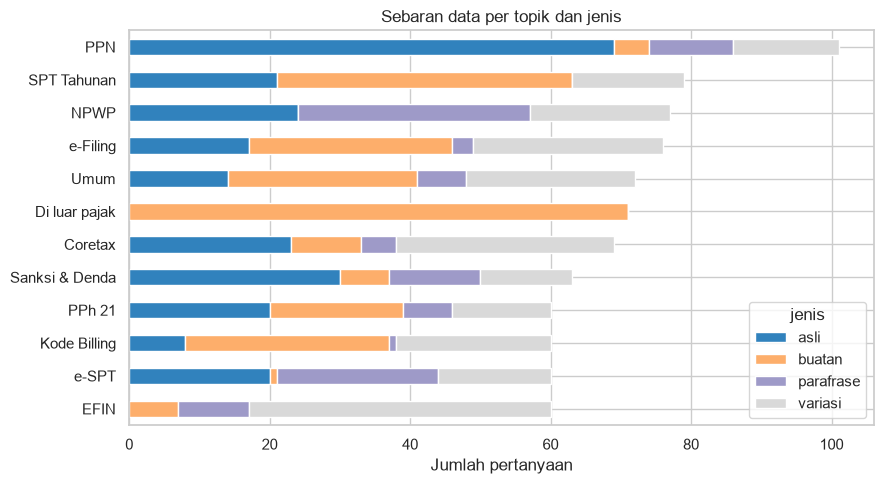

In [6]:
urutan = data['topik'].value_counts().index
tabel = pd.crosstab(data['topik'], data['jenis']).loc[urutan]

ax = tabel.plot(kind='barh', stacked=True, figsize=(9, 5), colormap='tab20c')
ax.invert_yaxis()
ax.set_title('Sebaran data per topik dan jenis')
ax.set_xlabel('Jumlah pertanyaan')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Penjelasan grafik:**

Grafik di atas memperlihatkan komposisi jenis data di setiap topik. Ada beberapa pola yang menarik:

- **PPN** didominasi pertanyaan asli (69 dari 101), karena FAQ resminya paling lengkap.
- Sebaliknya, **SPT Tahunan**, **Kode Billing**, dan **e-Filing** masih cukup bergantung pada pertanyaan buatan (masing-masing 42, 29, dan 29), karena FAQ resmi untuk topik ini sedikit.
- **EFIN** tidak punya pertanyaan asli sama sekali. Isinya parafrase (10) dan variasi (43).
- **e-SPT** hampir seluruhnya berasal dari FAQ (20 asli dan 23 parafrase), dengan hanya 1 pertanyaan buatan.
- **Di luar pajak** (71) seluruhnya pertanyaan buatan. Kelompok ini bukan topik pajak dan tidak ikut dilatih di model topik.

Jumlah data per topik pajak masih cukup seimbang (60 sampai 101 pertanyaan), tetapi komposisinya berbeda-beda. Karena itu saya memakai **F1-score makro** sebagai metrik utama, bukan hanya akurasi, supaya setiap topik punya bobot yang sama dan topik besar seperti PPN tidak menutupi kinerja topik yang lebih kecil.

## 4. Pemilihan Metode

### Pendekatan
**Natural Language Processing (NLP)** dengan **klasifikasi teks multikelas**: teks pertanyaan masuk, topik pajak keluar.

### Pra-pemrosesan
1. *Case folding* (huruf kecil)
2. Penyeragaman penulisan istilah (misalnya `e-SPT`, `e spt`, dan `eSPT` menjadi `espt`; `pph21` menjadi `pph 21`). Istilah berawalan *e-* sengaja digabung menjadi satu kata karena TF-IDF mengabaikan kata satu huruf. Jika dipecah, "e-SPT" terbaca sama dengan "SPT" sehingga topik e-SPT tertukar dengan SPT Tahunan.
3. Penghapusan tanda baca
4. Normalisasi kata tidak baku (misalnya `gmn` menjadi `bagaimana`, `dftr` menjadi `daftar`)
5. Penghapusan *stopword*
6. *Stemming* dengan Sastrawi

### Representasi teks
**TF-IDF** (unigram dan bigram). Kata yang jarang muncul tetapi khas pada suatu topik (misalnya *efin*, *coretax*) mendapat bobot lebih besar.

### Model yang dibandingkan
| Model | Alasan dipilih |
|---|---|
| **Multinomial Naive Bayes** (model utama, rencana awal) | Cepat, efektif untuk teks pendek dan data kecil, ringan untuk aplikasi |
| **Logistic Regression** | Pembanding linear yang juga memberi probabilitas untuk ambang keyakinan |
| **SVM linear** (`LinearSVC`) | Sering lebih akurat pada teks berdimensi tinggi. Probabilitasnya bisa didapat lewat kalibrasi (`CalibratedClassifierCV`) |
| *Dummy (kelas terbanyak)* | **Baseline** minimum sebagai pembanding |

> **Catatan:** Naive Bayes adalah model utama pada rencana awal (saya tulis ke dalam dokumen sesi 13). Model akhir tidak ditetapkan sejak awal, tetapi dipilih secara otomatis berdasarkan F1-score makro cross validation tertinggi di bagian 7. Pada hasil eksekusi notebook ini, model yang akhirnya saya pilih adalah **SVM linear**.

### Strategi evaluasi
- Pembagian **80% latih dan 20% uji** secara terstratifikasi, ditambah **stratified 5-fold cross validation** pada data latih.
- Pembagian dilakukan **per kelompok** (`StratifiedGroupKFold`): sebuah pertanyaan FAQ dan seluruh variasinya, serta pertanyaan buatan dalam satu `kelompok_makna`, selalu berada di sisi yang sama. Tanpa ini, rumusan berbeda dari pertanyaan yang sama muncul di data latih dan data uji, sehingga skor tampak lebih tinggi dari kemampuan sebenarnya (*data leakage*). Bagian 5.3 membuktikan efek ini dengan angka.
- Metrik: akurasi, precision, recall, dan F1-score per topik. **F1-score makro** menjadi metrik utama karena memberi bobot sama pada setiap topik.
- *Confusion matrix* untuk melihat topik yang sering tertukar.

## 5. Pengolahan Data

### 5.1 Pra-pemrosesan teks

In [7]:
#kamus normalisasi kata tidak baku yg disusun dari pola penulisan pengguna pada dataset
NORMALISASI = {
    'gmn': 'bagaimana', 'gmna': 'bagaimana', 'bgmn': 'bagaimana', 'gimana': 'bagaimana',
    'ga': 'tidak', 'gak': 'tidak', 'nggak': 'tidak', 'ngga': 'tidak', 'tdk': 'tidak',
    'yg': 'yang', 'dgn': 'dengan', 'dg': 'dengan', 'utk': 'untuk', 'untk': 'untuk',
    'dftr': 'daftar', 'dmn': 'dimana', 'bs': 'bisa', 'udh': 'sudah', 'udah': 'sudah',
    'sdh': 'sudah', 'blm': 'belum', 'lgs': 'langsung', 'krn': 'karena', 'karna': 'karena',
    'tgl': 'tanggal', 'bkn': 'bukan', 'sy': 'saya', 'gw': 'saya', 'gue': 'saya',
    'pake': 'pakai', 'bikin': 'buat', 'jg': 'juga', 'hrs': 'harus', 'lg': 'lagi',
    'apk': 'aplikasi',
    #tambahan setelah evaluasi pertanyaan bebas (lihat bagian 8.6): kata santai yang muncul di data variasi/buatan
    #dan set_setel, dipetakan ke bentuk baku yang dipakai FAQ resmi
    'pakai': 'gunakan', 'pake': 'gunakan', 'dipake': 'digunakan', 'pakenya': 'gunakan',
    'ilang': 'hilang', 'dapet': 'dapat', 'dapetnya': 'dapat', 'dapetin': 'mendapatkan',
    'dapetinnya': 'mendapatkan', 'deadline': 'batas waktu', 'diundur': 'ditunda',
    'telat': 'terlambat', 'kadaluarsa': 'daluwarsa', 'expired': 'daluwarsa',
    'ngapain': 'lakukan', 'amnesty': 'amnesti', 'pasword': 'password', 'diupload': 'upload',
    'install': 'instal', 'lemot': 'lambat', 'apaan': 'apa', 'msh': 'masih', 'tu': 'itu',
    'brp': 'berapa', 'padanin': 'padankan', 'aku': 'saya', 'ku': 'saya', 'gede': 'besar',
    'dibatalin': 'dibatalkan', 'batalin': 'batalkan', 'dilaporin': 'dilaporkan',
    'inget': 'ingat', 'telp': 'telepon', 'bikinnya': 'buatnya', 'dibikin': 'dibuat',
    'darimana': 'dari mana', 'kepotong': 'terpotong', 'tak': 'tidak', 'biling': 'billing',
    'kalo': 'kalau', 'onlen': 'online', 'skrg': 'sekarang', 'bbrp': 'beberapa',
    'kyk': 'seperti', 'gunanya': 'fungsinya', 'ttd': 'ditandatangani', 'jt': 'juta',
    'doang': 'saja', 'dr': 'dari', 'macem': 'macam',
}

#stopword dasar berupa kata fungsi yang tidak membedakan topik
STOPWORDS = {
    'yang', 'dan', 'di', 'ke', 'dari', 'untuk', 'dengan', 'apa', 'apakah', 'adalah',
    'itu', 'ini', 'atau', 'pada', 'dalam', 'saya', 'ya', 'dong', 'sih', 'nih', 'kah',
    'lah', 'aja', 'saja', 'bagaimana', 'kapan', 'mana', 'oleh', 'akan', 'agar', 'jika',
    'bila', 'sebagai', 'dapat', 'kalau', 'kok', 'deh', 'tuh', 'si',
}
if SASTRAWI_AKTIF:
    STOPWORDS |= set(StopWordRemoverFactory().get_stop_words())
    #notes: kata berikut membedakan topik/kalimat tanya, jadi tetap dipertahankan
    STOPWORDS -= {'tidak', 'belum', 'bukan'}

@lru_cache(maxsize=None)
def stem_kata(kata):
    return stemmer.stem(kata) if stemmer else kata

def bersihkan(teks):
    t = str(teks).lower()
    # 1. case folding
    # 2. penyeragaman istilah: "e-SPT", "e spt", "eSPT" -> "espt" (satu kata).
    #    Wajib digabung karena TF-IDF membuang kata satu huruf; jika dipecah jadi "e spt",
    #    "e-SPT" akan terbaca sama dengan "SPT" dan topik e-SPT tertukar dengan SPT Tahunan.
    t = re.sub(r'\be[-\s]?(filing|filling|faktur|spt|billing|bupot|form|objection)\b', r'e\1', t)
    t = re.sub(r'([a-z])(\d)', r'\1 \2', t)
    t = re.sub(r'(\d)([a-z])', r'\1 \2', t)
    t = re.sub(r'[^a-z0-9\s]', ' ', t)  # 3. hapus tanda baca
    kata = ' '.join(NORMALISASI.get(k, k) for k in t.split()).split() # 4. normalisasi kata tidak baku (hasilnya bisa 2 kata)
    kata = [k for k in kata if k not in STOPWORDS]  # 5. hapus stopword
    kata = [stem_kata(k) for k in kata] # 6. stemming jika Sastrawi aktif
    return ' '.join(kata)

contoh = ['dftr npwp online gmn',
          'Bagaimana penggunaan NPWP 16 digit pada aplikasi SAKTI dan SPAN?',
          'cara bikin e-faktur kalau pembeli ga punya npwp',
          'cara install e-SPT',
          'kapan batas lapor SPT Tahunan']
for c in contoh:
    print(f'{c!r}\n   -> {bersihkan(c)!r}\n')

'dftr npwp online gmn'
   -> 'daftar npwp online'

'Bagaimana penggunaan NPWP 16 digit pada aplikasi SAKTI dan SPAN?'
   -> 'guna npwp 16 digit aplikasi sakti span'

'cara bikin e-faktur kalau pembeli ga punya npwp'
   -> 'efaktur beli tidak npwp'

'cara install e-SPT'
   -> 'instal espt'

'kapan batas lapor SPT Tahunan'
   -> 'batas lapor spt tahun'



Contoh di atas menunjukkan setiap tahap pra-pemrosesan sudah bekerja sesuai rencana:

- `dftr npwp online gmn` menjadi `daftar npwp online`. Singkatan dinormalisasi lewat kamus (`dftr` = `daftar`, `gmn` = `bagaimana`), lalu kata tanya `bagaimana` dibuang karena termasuk stopword.
- `e-faktur` menjadi `efaktur` dan `e-SPT` menjadi `espt`. Istilah berawalan *e-* sengaja digabung menjadi satu kata, karena kalau dipecah menjadi "e spt", huruf "e" akan dibuang oleh TF-IDF dan "e-SPT" jadi terbaca sama dengan "SPT".
- Stemming Sastrawi mengubah kata ke bentuk dasarnya, misalnya `penggunaan` = `guna`, `pembeli` = `beli`, dan `Tahunan` = `tahun`. Dengan begitu, pertanyaan yang memakai bentuk kata berbeda (misalnya daftar, pendaftaran, mendaftar) tetap dianggap membahas hal yang sama.
- Stopword Sastrawi juga membuang kata umum seperti `cara`, `buat`, dan `punya`. Kata-kata ini muncul di hampir semua topik, jadi tidak membantu membedakan topik. Kata `tidak` sengaja saya pertahankan karena bisa mengubah makna pertanyaan.

Kamus normalisasi sempat saya perluas setelah menguji sistem dengan pertanyaan bebas (bagian 8.6). Misalnya `ilang` = `hilang`, `dapetin` = `mendapatkan`, `deadline` = `batas waktu`, `diundur` = `ditunda`, `pake` = `gunakan`, dan `kadaluarsa` = `daluwarsa`. Kata-kata tambahan ini hanya diambil dari data variasi/buatan dan set_setel, tidak dari set_kunci. Normalisasi juga boleh menghasilkan dua kata (`deadline` menjadi `batas waktu`), jadi hasilnya dipecah lagi sebelum masuk ke tahap stopword.

Hasilnya, teks menjadi jauh lebih pendek, tetapi kata kuncinya tetap tersisa, seperti `npwp`, `efaktur`, `espt`, dan `spt tahun`.

In [8]:
data['teks_bersih'] = data['pertanyaan'].apply(bersihkan)

#contoh pertanyaan bukan pajak hanya dipakai untuk melatih penyaring (bagian 8.1), bukan model topik
DI_LUAR_PAJAK = 'Di luar pajak'
data_pajak = data[data['topik'] != DI_LUAR_PAJAK]

#memastikan tidak ada teks yang kosong setelah pembersihan
print('Teks kosong setelah pembersihan:', (data['teks_bersih'].str.len() == 0).sum())
display(data_pajak[['pertanyaan', 'teks_bersih', 'topik']].sample(6, random_state=RANDOM_STATE))

Teks kosong setelah pembersihan: 0


,pertanyaan,teks_bersih,topik
568,bayar kurang bayar spt pakai kode billing apa,bayar bayar spt kode billing,Kode Billing
530,efin saya hilang,efin hilang,EFIN
610,sudah punya akun djp online perlu registrasi c...,akun djp online registrasi coretax,Coretax
109,Bagaimana jika data e-Faktur yang dimiliki PKP...,data efaktur milik pkp beda data djp,PPN
586,bayar billing pajak lewat m-banking,bayar billing pajak banking,Kode Billing
209,Kolom debit dan kredit pada menu accounting po...,kolom debit kredit menu accounting portal bala...,Coretax


Tidak ada pertanyaan yang menjadi kosong setelah dibersihkan (0), jadi seluruh 777 pertanyaan tetap bisa dipakai.

Dari enam sampel acak, terlihat pembersihan juga bekerja baik untuk pertanyaan bergaya santai. Misalnya `efin saya hilang` menjadi `efin hilang`, dan `bayar billing pajak lewat m-banking` menjadi `bayar billing pajak banking`. Kata yang tersisa memang kata yang paling mencirikan topiknya, seperti `efin`, `billing`, `coretax`, dan `efaktur`.

Ada satu efek samping kecil yang saya temukan: pada pertanyaan `bayar kurang bayar spt pakai kode billing apa`, kata `kurang` ikut terbuang karena termasuk stopword Sastrawi, padahal "kurang bayar" adalah istilah pajak. Untuk saat ini dampaknya kecil karena kata `spt` dan `kode billing` masih tersisa, tetapi daftar stopword ini bisa saya sesuaikan pada pengembangan berikutnya.

### 5.2 Pembagian data latih dan uji

Pembagian bersifat **terstratifikasi** (proporsi topik terjaga) dan **berkelompok** (pertanyaan yang maknanya sama tidak terpisah). Kolom `grup` dibentuk dengan urutan berikut:
1. Variasi memakai `induk_id`, sehingga bergabung dengan FAQ induknya.
2. Pertanyaan buatan memakai `kelompok_makna` bila ada.
3. Selain itu, data menjadi kelompok sendiri (`id`).

In [9]:
data['grup'] = data['induk_id'].fillna(data['kelompok_makna']).fillna(data['id'])
data_pajak = data[data['topik'] != DI_LUAR_PAJAK]
print('Jumlah kelompok:', data_pajak['grup'].nunique(), 'dari', len(data_pajak), 'pertanyaan')

X, y, grup = data_pajak['teks_bersih'], data_pajak['topik'], data_pajak['grup']

#stratifiedGroupKFold dengan 5 lipatan: satu lipatan (sekitar 20%) dipakai sebagai data uji
pembagi = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_latih, idx_uji = next(pembagi.split(X, y, grup))

X_latih, y_latih, g_latih = X.iloc[idx_latih], y.iloc[idx_latih], grup.iloc[idx_latih]
X_uji,   y_uji,   g_uji   = X.iloc[idx_uji],   y.iloc[idx_uji],   grup.iloc[idx_uji]

print(f'Data latih : {len(X_latih)} ({len(X_latih)/len(data_pajak):.0%})')
print(f'Data uji   : {len(X_uji)} ({len(X_uji)/len(data_pajak):.0%})')
print('Kelompok yang beririsan antara latih dan uji:', len(set(g_latih) & set(g_uji)))

sebaran = pd.DataFrame({'latih': y_latih.value_counts(), 'uji': y_uji.value_counts()}).fillna(0).astype(int)
sebaran['% uji'] = (sebaran['uji'] / (sebaran['latih'] + sebaran['uji']) * 100).round(1)
display(sebaran.sort_values('latih', ascending=False))

Jumlah kelompok: 514 dari 777 pertanyaan
Data latih : 627 (81%)
Data uji   : 150 (19%)
Kelompok yang beririsan antara latih dan uji: 0


,latih,uji,% uji
topik,,,
PPN,80,21,20.8
SPT Tahunan,63,16,20.3
e-Filing,63,13,17.1
NPWP,58,19,24.7
Umum,57,15,20.8
Sanksi & Denda,56,7,11.1
Coretax,52,17,24.6
PPh 21,52,8,13.3
e-SPT,50,10,16.7


Hasil pembagian data:

- 777 pertanyaan terbentuk menjadi **514 kelompok**. Artinya, ada pertanyaan yang "bersaudara" (FAQ beserta variasinya, atau pertanyaan buatan yang semakna) dan selalu dipindahkan bersama.
- Data latih berisi **627 pertanyaan (81%)** dan data uji **150 pertanyaan (19%)**, sudah mendekati rencana 80:20.
- `Kelompok yang beririsan antara latih dan uji: 0` membuktikan tidak ada satu pun kelompok yang terpecah, jadi tidak ada kebocoran data.

Dari tabel sebaran, proporsi data uji per topik tidak persis 20%. Misalnya Sanksi & Denda hanya 11,1% (7 pertanyaan), sedangkan NPWP 24,7% (19 pertanyaan). Hal ini wajar karena pembagian dilakukan per kelompok, bukan per pertanyaan, sehingga kelompok yang besar tidak bisa dipotong supaya pas 20%.

Konsekuensinya, skor per topik yang data ujinya sedikit, seperti Sanksi & Denda (7) dan PPh 21 (8), bisa naik-turun cukup jauh hanya karena satu atau dua pertanyaan. Jadi skor untuk topik-topik ini perlu dibaca dengan hati-hati.

### 5.3 Mengapa pembagian berkelompok, bukan acak biasa?

Sel berikut membandingkan dua cara pembagian 80:20 pada model yang sama (Logistic Regression), masing-masing diulang 5 kali dengan pengacakan berbeda:
- **Acak terstratifikasi biasa**: variasi dari FAQ yang sama bisa masuk ke data latih dan data uji sekaligus.
- **Berkelompok terstratifikasi**: cara yang dipakai di notebook ini.

In [10]:
from sklearn.model_selection import StratifiedShuffleSplit

def model_lr():
    return Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
                     ('clf', LogisticRegression(max_iter=2000, C=10, class_weight='balanced'))])

skor_acak, skor_kelompok = [], []
for seed in range(5):
    tr, te = next(StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(X, y))
    skor_acak.append(f1_score(y.iloc[te], model_lr().fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te]), average='macro'))
    tr, te = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed).split(X, y, grup))
    skor_kelompok.append(f1_score(y.iloc[te], model_lr().fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te]), average='macro'))

banding = pd.DataFrame({'F1 makro rata-rata': [np.mean(skor_acak), np.mean(skor_kelompok)],
                        'std': [np.std(skor_acak), np.std(skor_kelompok)]},
                       index=['Acak terstratifikasi biasa', 'Berkelompok terstratifikasi']).round(3)
display(banding)
print(f'Selisih: {np.mean(skor_acak) - np.mean(skor_kelompok):+.3f}')

,F1 makro rata-rata,std
Acak terstratifikasi biasa,0.900,0.022
Berkelompok terstratifikasi,0.835,0.028


Selisih: +0.065


Hasilnya cukup jelas. Dengan model yang sama, pembagian acak biasa menghasilkan F1 makro rata-rata **0,900**, sedangkan pembagian berkelompok hanya **0,835**. Selisihnya 0,065, dan hasil ini konsisten di lima kali pengulangan (standar deviasi 0,022 dan 0,028).

Skor yang lebih tinggi itu **bukan karena model lebih pintar**. Pada pembagian acak, rumusan lain dari pertanyaan yang sama (misalnya "cara daftar npwp gimana" dan "dftr npwp online gmn") bisa masuk ke data latih dan data uji sekaligus. Akibatnya, model sebenarnya hanya mengenali pertanyaan yang hampir sama dengan yang sudah pernah ia lihat.

Padahal, pengguna aplikasi nanti akan menulis pertanyaan yang benar-benar baru. Karena itu saya tetap memakai pembagian berkelompok. Walaupun skornya terlihat lebih rendah, gambaran kinerjanya lebih jujur dan lebih mendekati kondisi nyata.

### 5.4 Pengecekan kebocoran data uji ke data latih

Pembagian berkelompok memastikan FAQ dan variasinya tidak terpisah. Tapi bisa saja masih ada pertanyaan **dari kelompok berbeda** yang kalimatnya sangat mirip, misalnya dua pertanyaan buatan yang ternyata hampir sama. Kalau itu terjadi, data uji tetap bocor ke data latih walaupun kelompoknya berbeda.

Jadi di sini saya cek ulang dengan empat cara, dari yang paling ketat sampai yang paling longgar:
1. Apakah ada **kelompok** yang muncul di data latih dan data uji sekaligus.
2. Apakah ada **kalimat pertanyaan yang persis sama**.
3. Apakah ada pertanyaan yang **sama persis setelah pra-pemrosesan**.
4. Seberapa **mirip** setiap pertanyaan uji dengan pertanyaan latih yang paling dekat (cosine similarity TF-IDF). Sepuluh pasangan paling mirip ditampilkan supaya bisa saya periksa manual.

In [11]:
from sklearn.metrics.pairwise import cosine_similarity

cek_latih = data_pajak.iloc[idx_latih]
cek_uji = data_pajak.iloc[idx_uji].copy()

#1. kelompok yang sama tidak boleh muncul di kedua sisi
print('1. Kelompok yang muncul di latih dan uji :', len(set(cek_latih['grup']) & set(cek_uji['grup'])))

#2. kalimat pertanyaan yang persis sama
rapikan = lambda s: s.str.lower().str.strip()
print('2. Pertanyaan yang persis sama           :', len(set(rapikan(cek_latih['pertanyaan'])) & set(rapikan(cek_uji['pertanyaan']))))

#3. teks yang sama persis setelah pra-pemrosesan
teks_sama = sorted(set(cek_latih['teks_bersih']) & set(cek_uji['teks_bersih']))
print('3. Teks bersih yang identik              :', len(teks_sama), teks_sama)

#4. kemiripan tertinggi setiap pertanyaan uji terhadap seluruh data latih
vec_cek = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(cek_latih['teks_bersih'])
S = cosine_similarity(vec_cek.transform(cek_uji['teks_bersih']), vec_cek.transform(cek_latih['teks_bersih']))
cek_uji['kemiripan'] = S.max(axis=1)
cek_uji['paling_mirip_di_latih'] = cek_latih['pertanyaan'].to_numpy()[S.argmax(axis=1)]
cek_uji['topik_pasangan'] = cek_latih['topik'].to_numpy()[S.argmax(axis=1)]
print('4. Kemiripan tertinggi terhadap data latih:')
for batas in [0.7, 0.8, 0.9]:
    print(f'   >= {batas}: {(cek_uji["kemiripan"] >= batas).sum()} dari {len(cek_uji)} pertanyaan uji')

display(cek_uji.sort_values('kemiripan', ascending=False)
        [['pertanyaan', 'paling_mirip_di_latih', 'topik', 'topik_pasangan', 'kemiripan']].head(10).round(2))

1. Kelompok yang muncul di latih dan uji : 0
2. Pertanyaan yang persis sama           : 0
3. Teks bersih yang identik              : 3 ['kode billing', 'lapor spt online', 'tunjuk isi spt 1770']
4. Kemiripan tertinggi terhadap data latih:
   >= 0.7: 24 dari 150 pertanyaan uji
   >= 0.8: 16 dari 150 pertanyaan uji
   >= 0.9: 8 dari 150 pertanyaan uji


,pertanyaan,paling_mirip_di_latih,topik,topik_pasangan,kemiripan
732,Bagaimana petunjuk pengisian SPT 1770S?,Bagaimana petunjuk pengisian SPT 1770?,SPT Tahunan,SPT Tahunan,1.00
584,kode billing dapet dari mana,kode billing itu apa,Kode Billing,Kode Billing,1.00
580,cara bikin kode billing,kode billing itu apa,Kode Billing,Kode Billing,1.00
713,cara jadi konsultan pajak,apa itu pajak,Umum,Umum,1.00
361,lapor spt online harus punya apa aja,cara lapor spt online gimana,e-Filing,e-Filing,1.00
671,rasio pajak itu apa,apa itu pajak,Umum,Umum,1.00
369,suami istri lapor spt online sendiri-sendiri?,cara lapor spt online gimana,e-Filing,e-Filing,1.00
545,lupa efin lewat live chat bisa ga,lupa efin gimana,EFIN,EFIN,0.93
297,Apakah login DJP Online dengan NIK berarti dat...,login djp online pakai nik bisa?,NPWP,e-Filing,0.87
705,cara ajukan keberatan pajak,cara ajukan keberatan pajak online,Umum,Umum,0.86


Pengecekan nomor 1 dan 2 bernilai **0**. Artinya tidak ada kelompok yang terbelah dan tidak ada pertanyaan yang benar-benar sama di data latih dan data uji.

Untuk nomor 3 dan 4, nilai yang tidak nol belum tentu berarti bocor, jadi pasangannya saya periksa satu per satu. Ada tiga teks bersih yang identik, dan 16 dari 150 pertanyaan uji punya kemiripan 0,8 ke atas. Setelah dilihat, pasangan-pasangan ini bisa dikelompokkan menjadi tiga pola:

1. **Maksud berbeda, kata kunci sama.** Contohnya "cara bikin kode billing" dan "kode billing itu apa". Yang satu menanyakan cara membuat, yang satu menanyakan pengertian. Setelah pra-pemrosesan, kata seperti "cara", "itu", dan "apa" dibuang sebagai *stopword*, sehingga keduanya sama-sama tersisa "kode billing".
2. **Kata baru yang tidak dikenal data latih.** Contohnya "rasio pajak itu apa" dan "apa itu pajak", atau "cara jadi konsultan pajak" dan "apa itu pajak", yang skornya 1,00. Kemiripan dihitung dengan kosakata data latih saja, sehingga kata yang belum pernah muncul (seperti "rasio" dan "konsultan") tidak ikut dihitung. Jadi ini pertanyaan baru yang kebetulan berbagi kata kunci, bukan kebocoran.
3. **Dua FAQ resmi yang memang mirip.** "Bagaimana petunjuk pengisian SPT 1770S?" dan "Bagaimana petunjuk pengisian SPT 1770?" adalah dua FAQ berbeda dari DJP untuk dua formulir yang berbeda, jadi bukan duplikat. Tapi saat pra-pemrosesan, "1770S" dipecah menjadi "1770" dan "s", lalu huruf "s" dibuang karena TF-IDF mengabaikan token satu huruf. Akibatnya keduanya terbaca sama. Ini kelemahan kecil di pra-pemrosesan yang bisa diperbaiki ke depannya, misalnya dengan tidak memisahkan kode formulir seperti 1770S dan 1770SS.

Menariknya, tingginya kemiripan juga tidak menjamin topiknya sama. Contohnya "Apakah login DJP Online dengan NIK berarti data NIK sudah valid?" (NPWP) paling mirip dengan "login djp online pakai nik bisa?" (e-Filing). Jadi model tidak bisa sekadar "menyalin" label dari pertanyaan latih yang paling mirip.

Terakhir, saya cek apakah skor model sebenarnya hanya "terbantu" oleh pertanyaan uji yang sangat mirip dengan data latih. Caranya, SVM linear dilatih dengan data latih, lalu F1 makro dihitung dua kali: dengan seluruh data uji, dan tanpa pertanyaan uji yang kemiripannya 0,8 ke atas.

In [12]:
#apakah skor model bergantung pada pertanyaan uji yang sangat mirip dengan data latih?
svm_cek = Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
                    ('clf', LinearSVC(C=1.0, class_weight='balanced'))]).fit(X_latih, y_latih)
pred_cek = svm_cek.predict(X_uji)
aman = (cek_uji['kemiripan'] < 0.8).to_numpy()

print(f'F1 makro seluruh data uji ({len(aman)} pertanyaan)          : {f1_score(y_uji, pred_cek, average="macro"):.3f}')
print(f'F1 makro tanpa uji yang kemiripannya >= 0,8 ({aman.sum()} pertanyaan): '
      f'{f1_score(y_uji[aman], pred_cek[aman], average="macro"):.3f}')

F1 makro seluruh data uji (150 pertanyaan)          : 0.838
F1 makro tanpa uji yang kemiripannya >= 0,8 (134 pertanyaan): 0.821


Hasilnya, F1 makro pada seluruh 150 data uji adalah **0,838**, dan setelah 16 pertanyaan yang kemiripannya 0,8 ke atas dibuang, F1 makro pada 134 pertanyaan sisanya adalah **0,821**. Skornya turun 0,017, masih lebih kecil dari simpangan baku cross validation (0,026). Jadi model **tidak bergantung** pada pertanyaan uji yang hampir sama dengan data latih, dan skor evaluasi yang saya laporkan tetap bisa dipercaya. Hasil ini sekaligus menjawab masukan dosen agar dipastikan tidak ada data uji yang bocor ke data latih.

Penurunan kecil ini wajar, karena pertanyaan yang dibuang memang yang paling mudah ditebak (kata kuncinya jelas). Sebagai perbandingan, pembagian acak di bagian 5.3 menaikkan skor sebesar 0,065 karena kebocoran. Di sini tidak terlihat efek sebesar itu, sehingga pembagian berkelompok sudah cukup mencegah kebocoran data.

## 6. Implementasi Model

Setiap model dibungkus dalam *pipeline* (TF-IDF lalu pengklasifikasi) sehingga TF-IDF hanya dipelajari dari data latih pada setiap lipatan validasi. Cara ini mencegah kebocoran informasi dari data uji.

In [13]:
def buat_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=1)

model_kandidat = {
    'Baseline (kelas terbanyak)': Pipeline([('tfidf', buat_tfidf()),
                                            ('clf', DummyClassifier(strategy='most_frequent'))]),
    'Multinomial Naive Bayes':    Pipeline([('tfidf', buat_tfidf()),
                                            ('clf', MultinomialNB(alpha=0.1))]),
    'Logistic Regression':        Pipeline([('tfidf', buat_tfidf()),
                                            ('clf', LogisticRegression(max_iter=2000, C=10,
                                                                        class_weight='balanced'))]),
    'SVM linear':                 Pipeline([('tfidf', buat_tfidf()),
                                            ('clf', LinearSVC(C=1.0, class_weight='balanced'))]),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

hasil = []
model_terlatih = {}
for nama, model in model_kandidat.items():
    skor = cross_validate(model, X_latih, y_latih, groups=g_latih, cv=cv,
                          scoring=['accuracy', 'f1_macro'])
    model.fit(X_latih, y_latih)
    pred = model.predict(X_uji)
    model_terlatih[nama] = model
    hasil.append({
        'Model': nama,
        'CV akurasi': skor['test_accuracy'].mean(),
        'CV F1 makro': skor['test_f1_macro'].mean(),
        'CV F1 makro (std)': skor['test_f1_macro'].std(),
        'Uji akurasi': accuracy_score(y_uji, pred),
        'Uji F1 makro': f1_score(y_uji, pred, average='macro'),
    })

tabel_hasil = pd.DataFrame(hasil).set_index('Model').round(3)
display(tabel_hasil)

,CV akurasi,CV F1 makro,CV F1 makro (std),Uji akurasi,Uji F1 makro
Model,,,,,
Baseline (kelas terbanyak),0.130,0.021,0.004,0.140,0.022
Multinomial Naive Bayes,0.763,0.751,0.040,0.773,0.776
Logistic Regression,0.857,0.859,0.029,0.840,0.838
SVM linear,0.861,0.863,0.026,0.840,0.838


Dari tabel di atas, ada beberapa hal yang bisa saya lihat:

- **Baseline** (selalu menebak topik terbanyak, yaitu PPN) hanya mendapat F1 makro 0,021. Angka ini menjadi patokan paling bawah, dan semua model lain jauh di atasnya. Artinya, model memang benar-benar belajar dari isi teks, bukan sekadar menebak.
- **Naive Bayes** mendapat F1 makro 0,751 (CV) dan 0,776 (data uji), paling rendah di antara ketiga model.
- **Logistic Regression** (CV 0,859) dan **SVM linear** (CV 0,863) skornya sangat berdekatan. Selisihnya hanya 0,004, jauh lebih kecil dari standar deviasinya (0,026 sampai 0,029), jadi sebenarnya keduanya hampir setara.
- Di data uji, keduanya bahkan mendapat angka yang sama: akurasi 0,840 dan F1 makro 0,838.

Menurut saya, Naive Bayes kalah karena mengasumsikan setiap kata berdiri sendiri. Padahal pada pertanyaan yang pendek, kombinasi kata (bigram) seperti "kode billing" atau "lupa efin" sangat menentukan topik.

Model linear seperti Logistic Regression dan SVM bisa memberi bobot yang lebih tepat pada kata dan pasangan kata yang membedakan satu topik dari topik lainnya.

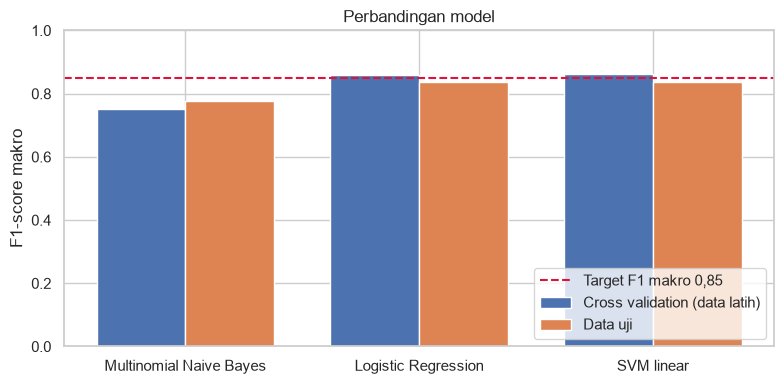

In [14]:
nama_model = tabel_hasil.index.drop('Baseline (kelas terbanyak)')
fig, ax = plt.subplots(figsize=(8, 4))
lebar = 0.38
pos = np.arange(len(nama_model))
ax.bar(pos - lebar/2, tabel_hasil.loc[nama_model, 'CV F1 makro'], lebar, label='Cross validation (data latih)')
ax.bar(pos + lebar/2, tabel_hasil.loc[nama_model, 'Uji F1 makro'], lebar, label='Data uji')
ax.axhline(0.85, color='crimson', linestyle='--', label='Target F1 makro 0,85')
ax.set_xticks(pos)
ax.set_xticklabels(nama_model)
ax.set_ylim(0, 1)
ax.set_ylabel('F1-score makro')
ax.set_title('Perbandingan model')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

Grafik ini memperlihatkan hal yang sama secara visual. Batang Naive Bayes jelas berada di bawah garis target 0,85. Untuk Logistic Regression dan SVM linear, batang cross validation (biru) sudah menyentuh atau sedikit melewati garis target, sedangkan batang data uji (oranye) sedikit di bawahnya.

Selisih kecil antara hasil cross validation dan data uji ini wajar. Data uji hanya berisi 150 pertanyaan dari satu kali pembagian, sedangkan cross validation adalah rata-rata dari lima pembagian, sehingga hasilnya lebih stabil.

Perbedaan antara 0,863 (cross validation) dan 0,838 (data uji) bukan tanda ada yang salah dengan model, tetapi efek dari cara mengukurnya.


Skor data uji 0,838 berasal dari satu kali pembagian berisi 150 pertanyaan, jadi bisa sedikit naik-turun tergantung pertanyaan yang terpilih. Cross validation merata-rata lima pembagian berbeda dan mendapat 0,863 dengan standar deviasi 0,026. Selisih keduanya masih di dalam rentang variasi itu, sehingga hasilnya konsisten.

## 7. Evaluasi Hasil

Model terbaik dipilih berdasarkan **F1-score makro hasil cross validation** (CV F1 Makro) bukan data uji, agar data uji tetap menjadi penilaian akhir yang bersih.

In [15]:
model_terbaik_nama = tabel_hasil.drop('Baseline (kelas terbanyak)')['CV F1 makro'].idxmax()
model_terbaik = model_terlatih[model_terbaik_nama]
pred_uji = model_terbaik.predict(X_uji)

print('Model terbaik (berdasarkan CV F1 makro):', model_terbaik_nama)
print('Akurasi data uji  :', round(accuracy_score(y_uji, pred_uji), 3))
print('F1 makro data uji :', round(f1_score(y_uji, pred_uji, average='macro'), 3))
print()
print(classification_report(y_uji, pred_uji, digits=3, zero_division=0))

Model terbaik (berdasarkan CV F1 makro): SVM linear
Akurasi data uji  : 0.84
F1 makro data uji : 0.838

                precision    recall  f1-score   support

       Coretax      1.000     0.588     0.741        17
          EFIN      1.000     1.000     1.000        12
  Kode Billing      1.000     0.667     0.800        12
          NPWP      0.895     0.895     0.895        19
           PPN      0.870     0.952     0.909        21
        PPh 21      0.875     0.875     0.875         8
   SPT Tahunan      0.812     0.812     0.812        16
Sanksi & Denda      0.667     0.857     0.750         7
          Umum      0.786     0.733     0.759        15
      e-Filing      0.600     0.923     0.727        13
         e-SPT      0.909     1.000     0.952        10

      accuracy                          0.840       150
     macro avg      0.856     0.846     0.838       150
  weighted avg      0.864     0.840     0.839       150



Berdasarkan F1 makro cross validation, model terbaik yang terpilih adalah **SVM linear** (0,863). Pemilihan ini sengaja memakai hasil cross validation, bukan data uji, supaya data uji tetap menjadi penilaian akhir yang bersih. Pada data uji, SVM linear mendapat akurasi **0,840** dan F1 makro **0,838**.

Kalau dilihat per topik:

- **Paling baik:** EFIN (F1 1,000), e-SPT (0,952), PPN (0,909), dan NPWP (0,895). Hasil e-SPT ini menunjukkan bahwa penggabungan istilah berawalan *e-* berhasil, karena sebelumnya topik ini sering tertukar dengan SPT Tahunan.
- **Coretax** (F1 0,741) memiliki precision 1,000 tetapi recall hanya 0,588. Artinya, setiap kali model menebak Coretax, tebakannya selalu benar, tetapi ada 7 dari 17 pertanyaan Coretax yang tidak dikenali dan malah ditebak sebagai topik lain.
- **Sanksi & Denda** (F1 0,750) justru kebalikannya: recall 0,857 tetapi precision hanya 0,667, karena ada pertanyaan dari topik lain yang ikut ditebak sebagai Sanksi & Denda. Data ujinya juga hanya 7, jadi skornya sangat sensitif.
- **Kode Billing** (recall 0,667) dan **e-Filing** (precision 0,600) juga masih perlu diperbaiki.

Jadi, kelemahan model tidak merata di semua topik, tetapi terkumpul di beberapa topik yang cakupannya luas atau kosakatanya bersinggungan dengan topik lain.

### Confusion matrix
Baris menunjukkan topik sebenarnya dan kolom menunjukkan topik prediksi. Angka di luar diagonal adalah kesalahan.

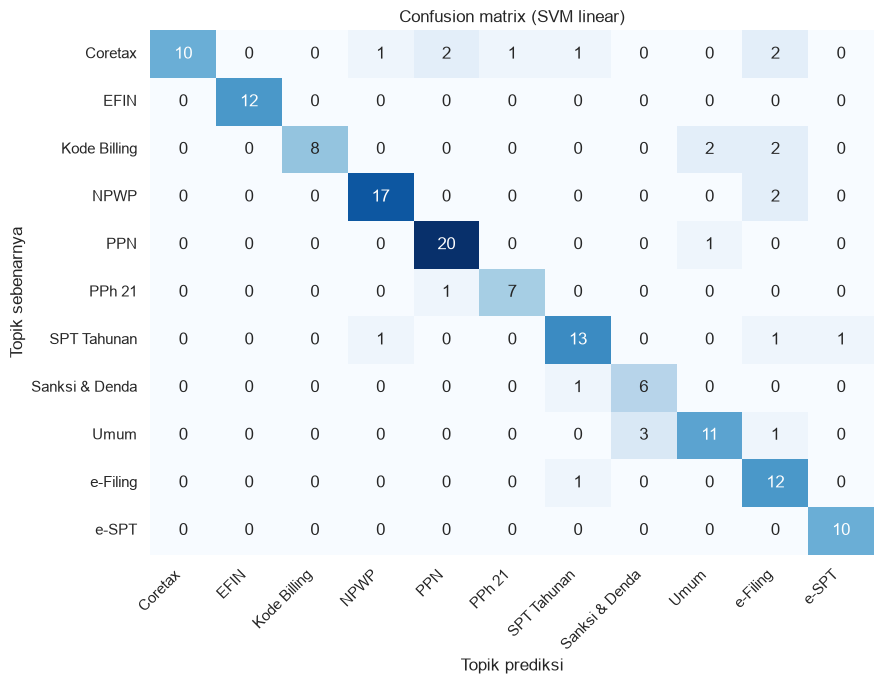

Pasangan topik yang paling sering tertukar (sebenarnya -> prediksi):
  Umum -> Sanksi & Denda: 3 pertanyaan
  Coretax -> PPN: 2 pertanyaan
  Coretax -> e-Filing: 2 pertanyaan
  Kode Billing -> Umum: 2 pertanyaan
  Kode Billing -> e-Filing: 2 pertanyaan


In [16]:
label = sorted(y.unique())
cm = confusion_matrix(y_uji, pred_uji, labels=label)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=label, yticklabels=label)
plt.xlabel('Topik prediksi')
plt.ylabel('Topik sebenarnya')
plt.title(f'Confusion matrix ({model_terbaik_nama})')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#pasangan topik yang paling sering tertukar
pasangan = [(label[i], label[j], cm[i, j]) for i in range(len(label))
            for j in range(len(label)) if i != j and cm[i, j] > 0]
pasangan = sorted(pasangan, key=lambda p: -p[2])[:5]
print('Pasangan topik yang paling sering tertukar (sebenarnya -> prediksi):')
for a, b, n in pasangan:
    print(f'  {a} -> {b}: {n} pertanyaan')

Pada confusion matrix, angka di diagonal adalah prediksi yang benar, sedangkan angka di luar diagonal adalah kesalahan. Beberapa hal yang terlihat:

- **EFIN (12/12)** dan **e-SPT (10/10)** diprediksi benar semua, dan **PPN** hampir sempurna (20/21).
- Kesalahan paling banyak berasal dari baris **Coretax**. Sebanyak 7 pertanyaannya tersebar ke 5 topik berbeda: PPN (2), e-Filing (2), NPWP (1), PPh 21 (1), dan SPT Tahunan (1). Ini masuk akal, karena Coretax adalah sistem baru yang dipakai untuk hampir semua urusan pajak (faktur, bukti potong, SPT), sehingga kosakatanya sangat mirip dengan topik lain.
- Pasangan yang paling sering tertukar adalah **Umum → Sanksi & Denda** (3 pertanyaan). Ini yang menjelaskan kenapa precision Sanksi & Denda rendah.
- **Kode Billing** tertukar 2 kali menjadi Umum dan 2 kali menjadi e-Filing. Ini juga yang membuat precision e-Filing rendah.

Yang cukup menggembirakan, e-SPT dan SPT Tahunan sekarang hampir tidak tertukar lagi. Hanya ada 1 pertanyaan SPT Tahunan yang ditebak sebagai e-SPT.

### Analisis kesalahan
Pertanyaan yang salah diprediksi pada data uji diperiksa untuk memahami penyebabnya.

In [17]:
uji = data_pajak.iloc[idx_uji].copy()
uji['prediksi'] = pred_uji
salah = uji[uji['topik'] != uji['prediksi']][['pertanyaan', 'topik', 'prediksi', 'jenis']]
print(f'Jumlah salah prediksi: {len(salah)} dari {len(uji)}')
pd.set_option('display.max_colwidth', 90)
display(salah.head(15))

Jumlah salah prediksi: 24 dari 150


,pertanyaan,topik,prediksi,jenis
27,Berapa kali Wajib Pajak dapat melakukan pembetulan SPT di tahun 2015 atas suatu masa p...,Sanksi & Denda,SPT Tahunan,parafrase
197,Apakah cabang dapat menerbitkan bukti potong?,Coretax,PPh 21,asli
202,"Setelah pemusatan, apakah ketetapan PPN langsung dipusatkan atau KPP cabang menerima p...",Coretax,PPN,parafrase
204,Apakah NITKU dari penyedia barang/jasa bersifat mandatory atau opsional dalam pembuata...,Coretax,PPN,asli
209,"Kolom debit dan kredit pada menu accounting portal/balance sheet di Tax Payer Portal, ...",Coretax,NPWP,asli
216,Apakah Wajib Pajak berisiko rendah yang kesulitan likuiditas bisa mengajukan angsuran ...,Kode Billing,e-Filing,parafrase
249,Sektor wisata apakah ada syarat ketentuan? Apakah termasuk persewaan bis wisata?,PPh 21,PPN,asli
295,Saat kami unduh file konfirmasi lalu memasukkan PIN namun filenya tidak bisa dibuka,NPWP,e-Filing,asli
297,Apakah login DJP Online dengan NIK berarti data NIK sudah valid?,NPWP,e-Filing,parafrase
343,spt 1770 ss bisa lewat e-filing?,e-Filing,SPT Tahunan,buatan


Ada **24 pertanyaan yang salah diprediksi dari 150** (sekitar 16%). Setelah saya periksa 15 contoh yang ditampilkan, polanya bisa dikelompokkan menjadi tiga:

1. **Pertanyaan Coretax yang tidak menyebut kata "Coretax".** Contohnya, "Apakah cabang dapat menerbitkan bukti potong?" ditebak PPh 21, dan pertanyaan tentang NITKU dalam pembuatan bukti potong ditebak PPN. Kalau hanya dilihat dari teksnya, pertanyaan ini memang lebih mirip topik PPh 21 atau PPN, sehingga model sulit mengetahui bahwa konteksnya adalah fitur Coretax.
2. **Topik yang isinya memang bersinggungan.** Misalnya "pajak bisa dicicil ga" dan "ajukan angsuran tunggakan pajak online" berlabel Kode Billing tetapi ditebak Umum dan e-Filing. Lalu "istri ikut npwp suami, spt nya gimana" berlabel SPT Tahunan tetapi ditebak NPWP. Kalau dibaca manusia pun, pertanyaan seperti ini bisa masuk ke lebih dari satu topik.
3. **Kata kunci yang "menyesatkan".** "spt 1771 itu untuk apa" ditebak e-SPT karena kode formulir 1771 sering muncul di FAQ e-SPT. Sementara itu, "spt 1770 ss bisa lewat e-filing?" ditebak SPT Tahunan karena "spt 1770 ss" lebih sering muncul di topik tersebut.

Dari pola ini, perbaikan ke depan bukan hanya soal menambah jumlah data. Yang lebih penting adalah menambah contoh yang bisa membedakan topik-topik yang mirip, serta meninjau ulang label pertanyaan yang memang ambigu bersama praktisi pajak.

In [18]:
#kinerja berdasarkan jenis data, apakah model lebih sulit pada bahasa sehari-hari?
uji['benar'] = uji['topik'] == uji['prediksi']
per_jenis = uji.groupby('jenis')['benar'].agg(['mean', 'count']).round(3)
per_jenis.columns = ['akurasi', 'jumlah data uji']
display(per_jenis)

,akurasi,jumlah data uji
jenis,,
asli,0.830,47
buatan,0.811,37
parafrase,0.840,25
variasi,0.878,41


Tabel ini menjawab pertanyaan yang cukup penting: apakah model kesulitan memahami bahasa sehari-hari? Ternyata **tidak**. Akurasi pada **variasi** (bahasa santai, singkatan, dan salah ketik) mencapai 0,878, malah lebih tinggi daripada **parafrase** (0,840) dan pertanyaan **asli** (0,830).

Pertanyaan asli lebih sulit kemungkinan karena kalimatnya panjang, formal, dan teknis, serta sering membahas hal yang sangat spesifik (misalnya PMK tertentu atau fitur tertentu di Coretax). Pertanyaan **buatan** memiliki akurasi paling rendah (0,811) karena tidak punya padanan di FAQ, sehingga tidak ada pertanyaan "saudara" di data latih yang bisa membantu model.

Hasil ini menunjukkan bahwa normalisasi kata tidak baku dan data augmentation sudah membantu model memahami gaya bahasa pengguna.

### Uji tambahan dengan pertanyaan di luar dataset
Strategi evaluasi mencakup data uji tambahan yang **tidak ada di dataset** agar model tidak hanya dinilai dengan gaya bahasa dataset sendiri. Daftar di bawah berisi 22 pertanyaan bergaya bahasa sehari-hari (2 per topik) yang **ditulis dengan bantuan AI dan diverifikasi oleh praktisi pajak**, termasuk label topiknya. Data ini tidak pernah dipakai saat pelatihan.

In [19]:
uji_tambahan = [
    ('cara bikin npwp online gimana ya', 'NPWP'),
    ('npwp saya hilang, urus ulang dimana', 'NPWP'),
    ('lupa password djp online, cara reset', 'e-Filing'),
    ('gimana cara kirim spt lewat efiling', 'e-Filing'),
    ('batas akhir lapor spt tahunan pribadi kapan', 'SPT Tahunan'),
    ('spt tahunan nihil perlu dilaporkan ga', 'SPT Tahunan'),
    ('gaji karyawan dipotong pph 21 berapa persen', 'PPh 21'),
    ('bukti potong 1721 a1 dapat dari mana', 'PPh 21'),
    ('pkp wajib bikin faktur pajak ga', 'PPN'),
    ('faktur pajak dibuat paling lambat kapan', 'PPN'),
    ('telat lapor spt kena denda berapa', 'Sanksi & Denda'),
    ('bunga penagihan pajak dihitung gimana', 'Sanksi & Denda'),
    ('cara dapat efin baru', 'EFIN'),
    ('efin hilang gimana', 'EFIN'),
    ('cara bikin kode billing bayar pajak', 'Kode Billing'),
    ('kode billing kadaluarsa berapa lama', 'Kode Billing'),
    ('cara login coretax pertama kali', 'Coretax'),
    ('aktivasi akun coretax gimana', 'Coretax'),
    ('cara pasang aplikasi espt', 'e-SPT'),
    ('import csv ke espt ppn gimana', 'e-SPT'),
    ('pajak itu apa sih fungsinya', 'Umum'),
    ('hubungi kring pajak lewat nomor berapa', 'Umum'),
]
df_tambahan = pd.DataFrame(uji_tambahan, columns=['pertanyaan', 'topik'])
df_tambahan['prediksi'] = model_terbaik.predict(df_tambahan['pertanyaan'].apply(bersihkan))

acc_tambahan = accuracy_score(df_tambahan['topik'], df_tambahan['prediksi'])
f1_tambahan = f1_score(df_tambahan['topik'], df_tambahan['prediksi'], average='macro')
print(f'Akurasi uji tambahan  : {acc_tambahan:.3f}  ({len(df_tambahan)} pertanyaan)')
print(f'F1 makro uji tambahan : {f1_tambahan:.3f}')
display(df_tambahan[df_tambahan['topik'] != df_tambahan['prediksi']])

Akurasi uji tambahan  : 0.955  (22 pertanyaan)
F1 makro uji tambahan : 0.952


,pertanyaan,topik,prediksi
7,bukti potong 1721 a1 dapat dari mana,PPh 21,e-SPT


Pada 22 pertanyaan di luar dataset, model menebak benar **21 pertanyaan** (akurasi 0,955, F1 makro 0,952). Satu-satunya kesalahan adalah "bukti potong 1721 a1 dapat dari mana", yang berlabel PPh 21 tetapi ditebak e-SPT. Penyebabnya mirip dengan analisis kesalahan sebelumnya: istilah "1721-A1" banyak muncul di FAQ e-SPT (misalnya cara mengubah atau menghapus bukti potong 1721-A1 di e-SPT), sehingga model mengaitkannya ke topik e-SPT.

Skor ini lebih tinggi daripada skor data uji (0,841), tetapi saya tidak menjadikannya patokan utama karena jumlahnya hanya 22 pertanyaan (2 per topik). Satu kesalahan saja sudah mengubah akurasi sekitar 4,5%. Jadi hasil ini lebih tepat dibaca sebagai tanda awal bahwa model bisa menangani pertanyaan baru yang bergaya santai.

## 8. Model Akhir dan Demo

Model akhir dilatih ulang dengan **seluruh 777 pertanyaan pajak**, lalu disimpan untuk dipakai oleh API (FastAPI) untuk membuat website/mobileApps.

Aturan keyakinan: bila probabilitas tertinggi **di bawah 50%**, sistem tidak menebak, melainkan menawarkan topik terdekat dan menyarankan pengguna menghubungi Kring Pajak.

In [20]:
AMBANG_KEYAKINAN = 0.50

#linearSVC tidak menghasilkan probabilitas, sehingga dikalibrasi bila menjadi model terbaik
if hasattr(model_terbaik, 'predict_proba'):
    model_final = model_kandidat[model_terbaik_nama]
else:
    model_final = CalibratedClassifierCV(model_kandidat[model_terbaik_nama], cv=3)
model_final.fit(X, y)

joblib.dump({'model': model_final, 'ambang': AMBANG_KEYAKINAN}, 'model_tanyapajak.joblib')
print('Model disimpan: model_tanyapajak.joblib')

def tanya_pajak(pertanyaan):
    teks = bersihkan(pertanyaan)
    proba = model_final.predict_proba([teks])[0]
    urut = np.argsort(proba)[::-1]
    kelas = model_final.classes_
    print(f'Pertanyaan: {pertanyaan}')
    if proba[urut[0]] >= AMBANG_KEYAKINAN:
        print(f'  Topik terdeteksi: {kelas[urut[0]]} (keyakinan {proba[urut[0]]:.0%})')
    else:
        print(f'  Keyakinan rendah ({proba[urut[0]]:.0%}). Topik terdekat: '
              f'{kelas[urut[0]]} ({proba[urut[0]]:.0%}), {kelas[urut[1]]} ({proba[urut[1]]:.0%})')
        print('  Saran: hubungi Kring Pajak di 1500200 untuk jawaban yang pasti.')
    print()

for q in ['dftr npwp online gmn',
          'cara lapor spt di coretax',
          'telat bayar pajak dendanya berapa',
          'resep nasi goreng enak']:
    tanya_pajak(q)

Model disimpan: model_tanyapajak.joblib
Pertanyaan: dftr npwp online gmn
  Topik terdeteksi: NPWP (keyakinan 84%)

Pertanyaan: cara lapor spt di coretax
  Topik terdeteksi: Coretax (keyakinan 85%)

Pertanyaan: telat bayar pajak dendanya berapa
  Topik terdeteksi: Sanksi & Denda (keyakinan 68%)

Pertanyaan: resep nasi goreng enak
  Keyakinan rendah (23%). Topik terdekat: Umum (23%), PPN (14%)
  Saran: hubungi Kring Pajak di 1500200 untuk jawaban yang pasti.



Karena model terbaiknya adalah SVM linear, yang secara bawaan tidak mengeluarkan probabilitas, model dibungkus dengan `CalibratedClassifierCV` supaya bisa menghasilkan tingkat keyakinan untuk aturan ambang 50%. Model akhir dilatih dengan seluruh 777 pertanyaan dan disimpan sebagai `model_tanyapajak.joblib`.

Hasil demonya:

- "dftr npwp online gmn": **NPWP (84%)** dan "cara lapor spt di coretax", **Coretax (85%)**. Keduanya ditebak benar dengan keyakinan tinggi, padahal pertanyaan pertama ditulis dengan singkatan.
- "telat bayar pajak dendanya berapa": **Sanksi & Denda (68%)**. Tebakannya benar, tetapi keyakinannya lebih rendah dari dua contoh pertama. Kemungkinan karena kata "bayar" juga sering muncul di topik Kode Billing.
- "resep nasi goreng enak": keyakinan tertingginya hanya **23%**, sehingga sistem tidak memaksakan jawaban dan menyarankan pengguna menghubungi Kring Pajak.

Contoh terakhir menunjukkan bahwa aturan ambang keyakinan bekerja sesuai rencana: pertanyaan yang tidak berhubungan dengan pajak tidak dijawab asal-asalan.

### 8.1 Penyaring pertanyaan di luar pajak

Model topik selalu memilih salah satu dari 11 topik pajak. Akibatnya, pertanyaan yang sama sekali bukan tentang pajak, misalnya "cara bikin sim online", tetap ditebak sebagai salah satu topik, kadang dengan keyakinan tinggi. Supaya pertanyaan seperti ini bisa ditolak dengan sopan, saya menambahkan **penyaring** di depan model topik. Penyaring ini adalah model kecil yang hanya membedakan *pajak* dan *bukan pajak*.

- **Data latih:** seluruh dataset, yaitu 777 pertanyaan pajak ditambah **71 contoh pertanyaan bukan pajak** (topik `Di luar pajak`). Contohnya urusan KTP dan paspor, rekening bank, aplikasi HP, sampai pertanyaan sehari-hari. Contoh bukan pajak ini sengaja **tidak memakai tema** yang ada di set uji bebas (bagian 8.6), supaya hasil uji tetap jujur.
- **Model:** SVM linear dengan TF-IDF unigram dan bigram, lalu dikalibrasi seperti model topik. Pertanyaan dianggap bukan pajak jika peluangnya minimal 50%.
- **Kenapa tidak dijadikan kelas ke-12 di model topik?** Cara ini sudah saya coba. Penolakannya memang lebih banyak, tetapi F1 makro cross validation model topik turun dari 0,863 menjadi 0,798, sehingga target 0,85 tidak tercapai, dan dua pertanyaan pajak di uji tambahan jadi salah topik. Dengan penyaring terpisah, model topik tidak berubah sama sekali.


In [21]:
from sklearn.model_selection import cross_val_predict

#penyaring: 1 = bukan pajak, 0 = pajak. Dilatih dengan seluruh data, termasuk contoh Di luar pajak
AMBANG_PENYARING = 0.50
y_penyaring = (data['topik'] == DI_LUAR_PAJAK).astype(int)

def buat_penyaring():
    return CalibratedClassifierCV(Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
                                            ('clf', LinearSVC(C=1.0, class_weight='balanced'))]), cv=3)

#evaluasi dengan cross validation berkelompok, sama seperti model topik
pred_cv = cross_val_predict(buat_penyaring(), data['teks_bersih'], y_penyaring, groups=data['grup'], cv=cv)
print(classification_report(y_penyaring, pred_cv, target_names=['pajak', 'bukan pajak'], digits=3))
print('Pertanyaan pajak yang ikut tersaring:')
display(data[(y_penyaring == 0) & (pred_cv == 1)][['pertanyaan', 'topik']])

penyaring = buat_penyaring().fit(data['teks_bersih'], y_penyaring)
lolos = penyaring.predict_proba(df_tambahan['pertanyaan'].apply(bersihkan))[:, 1] < AMBANG_PENYARING
print(f'Uji tambahan (22 pertanyaan pajak) yang lolos penyaring: {lolos.sum()} dari {len(lolos)}')
for q in ['dftr npwp online gmn', 'resep nasi goreng enak']:
    print(f'  {q!r}: peluang bukan pajak {penyaring.predict_proba([bersihkan(q)])[0, 1]:.0%}')


              precision    recall  f1-score   support

       pajak      0.934     0.996     0.964       777
 bukan pajak      0.842     0.225     0.356        71

    accuracy                          0.932       848
   macro avg      0.888     0.611     0.660       848
weighted avg      0.926     0.932     0.913       848

Pertanyaan pajak yang ikut tersaring:


,pertanyaan,topik
348,cara cek spt sudah terkirim atau belum,e-Filing
698,jam buka kantor pajak,Umum
744,Bagaimana apabila Saya lupa password dan Email?,e-Filing


Uji tambahan (22 pertanyaan pajak) yang lolos penyaring: 22 dari 22
  'dftr npwp online gmn': peluang bukan pajak 18%
  'resep nasi goreng enak': peluang bukan pajak 24%


Hasil penyaring:

- Penyaring hampir tidak pernah salah menolak pertanyaan pajak. Dari 777 pertanyaan pajak, hanya 3 yang ikut tersaring pada cross validation (recall pajak 0,996), dan seluruh 22 pertanyaan uji tambahan lolos. Salah satu yang tersaring adalah "jam buka kantor pajak", karena polanya mirip contoh bukan pajak "jam buka mall hari minggu".
- Sebaliknya, penyaring baru mengenali **22,5%** pertanyaan bukan pajak yang belum pernah dilihatnya (recall bukan pajak 0,225, precision 0,842). Ini wajar, karena contoh bukan pajak sangat beragam dan setiap contoh membahas hal yang berbeda, sedangkan TF-IDF hanya mengenali kata yang pernah muncul di data latih. Contohnya "resep nasi goreng enak" hanya mendapat peluang 24%.
- Karena itu, penyaring bukan satu-satunya pengaman. Pertanyaan bukan pajak yang lolos penyaring biasanya masih tertahan di langkah berikutnya: keyakinan topik di bawah 50%, atau tidak ada FAQ dengan skor minimal 0,40. Hasil gabungannya diukur di bagian 8.6.


### 8.2 Pencarian Jawaban Dua Tahap

Model klasifikasi di atas baru bisa menebak **topik**. Supaya aplikasi bisa menampilkan **jawaban**, saya menambahkan tahap kedua. Sebelum masuk ke dua tahap ini, pertanyaan lebih dulu melewati penyaring di bagian 8.1.

1. **Tahap 1 (klasifikasi):** model menebak topik pertanyaan. Jika keyakinannya di bawah 50%, sistem berhenti dan menyarankan Kring Pajak.
2. **Tahap 2 (pencarian):** di dalam topik tersebut, sistem mencari pertanyaan FAQ yang **paling mirip** dengan pertanyaan pengguna menggunakan TF-IDF dan *cosine similarity*, lalu menampilkan jawaban dan sumber resminya. Kalau di topik itu tidak ada FAQ yang cukup mirip, pencarian diulang di **seluruh topik**, karena ada FAQ yang tersimpan di topik lain (misalnya cara lapor SPT di Coretax ada di topik SPT Tahunan).

Beberapa keputusan desain:
- **Indeks pencarian** berisi pertanyaan FAQ (asli dan parafrase) **ditambah seluruh variasinya**. Setiap variasi menunjuk ke FAQ induknya, sehingga pertanyaan santai seperti "dftr npwp online gmn" bisa cocok dengan variasi yang mirip lalu diarahkan ke jawaban FAQ induknya.
- Representasi teks memakai gabungan **TF-IDF kata** (unigram dan bigram) dan **TF-IDF karakter** (potongan 3 sampai 5 huruf), supaya lebih tahan terhadap salah ketik dan singkatan.
- Selain pertanyaan, **teks jawaban** FAQ juga ikut dicocokkan. Skor sebuah FAQ = **0,6 × kemiripan pertanyaan** (yang tertinggi di antara pertanyaan FAQ dan variasinya) + **0,4 × kemiripan jawaban**. Pertanyaan diberi bobot lebih besar karena gaya bahasanya paling dekat dengan pertanyaan pengguna, sedangkan jawaban membantu saat pengguna memakai kata yang hanya muncul di isi jawaban (misalnya "ditunda" atau "7 hari").
- Pertanyaan buatan tidak dimasukkan ke indeks karena tidak memiliki jawaban resmi.
- Jika skor tertinggi di bawah **0,40**, sistem tidak memaksakan jawaban dan menyarankan Kring Pajak. Awalnya ambang ini 0,20, lalu disetel ulang setelah evaluasi (bagian 8.6).
- Sebagian kecil jawaban hanya berisi rujukan ke berkas di halaman sumber (misalnya petunjuk pengisian SPT 1770 SS dalam bentuk PDF). Untuk jawaban seperti ini, tautan sumbernya ditambahkan langsung di akhir jawaban.

Kolom `jawaban` pada dataset berisi ringkasan jawaban dari halaman sumber resmi, dan aplikasi selalu menampilkan tautan sumbernya agar pengguna bisa membaca jawaban lengkap.

In [22]:
from scipy.sparse import hstack
from sklearn.metrics.pairwise import cosine_similarity
import textwrap

KEMIRIPAN_MIN = 0.40  #di bawah nilai ini, sistem tidak memilih FAQ tertentu (awalnya 0.20, lihat bagian 8.6)
BOBOT_PERTANYAAN = 0.6  #skor FAQ = 0,6 x kemiripan pertanyaan + 0,4 x kemiripan jawaban

#bank jawaban: FAQ resmi yang sudah memiliki jawaban
faq_dengan_jawaban = data[data['jawaban'].notna()].set_index('id')
faq_dengan_jawaban['jawaban_bersih'] = faq_dengan_jawaban['jawaban'].apply(bersihkan)

#indeks pencarian: FAQ + seluruh variasinya (variasi menunjuk ke FAQ induknya)
indeks = data[data['jenis'].isin(['asli', 'parafrase', 'variasi'])].copy()
indeks['faq_id'] = indeks['induk_id'].fillna(indeks['id'])
indeks = indeks[indeks['faq_id'].isin(faq_dengan_jawaban.index)]
indeks = indeks.reset_index().rename(columns={'index': 'baris_asal'})

#TF-IDF kata + TF-IDF karakter, dipelajari dari teks pertanyaan dan jawaban FAQ
korpus = pd.concat([indeks['teks_bersih'], faq_dengan_jawaban['jawaban_bersih']])
vec_kata = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(korpus)
vec_huruf = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), sublinear_tf=True).fit(korpus)

def vektor(daftar_teks):
    m = hstack([vec_kata.transform(daftar_teks), vec_huruf.transform(daftar_teks)]).tocsr()
    norma = np.sqrt(np.asarray(m.multiply(m).sum(axis=1))).ravel()
    norma[norma == 0] = 1
    return m.multiply(1 / norma[:, None]).tocsr()

M_indeks = vektor(indeks['teks_bersih'])
M_jawaban = vektor(faq_dengan_jawaban['jawaban_bersih'])  #satu baris per FAQ, urutannya sama dengan faq_dengan_jawaban

def cari_faq(teks_bersih, topik, k=3, kecuali=None):
    """Mencari k FAQ paling mirip di dalam satu topik (topik=None: di seluruh topik).
    kecuali: array boolean baris indeks yang tidak boleh dipakai (khusus untuk evaluasi)."""
    mask = np.ones(len(indeks), bool) if topik is None else (indeks['topik'] == topik).to_numpy()
    if kecuali is not None:
        mask = mask & ~kecuali
    q = vektor([teks_bersih])
    #kemiripan pertanyaan: ambil yang tertinggi di antara pertanyaan FAQ dan variasinya
    skor_p = (indeks[mask].assign(skor=cosine_similarity(q, M_indeks[mask]).ravel())
              .groupby('faq_id')['skor'].max())
    skor_j = pd.Series(cosine_similarity(q, M_jawaban).ravel(), index=faq_dengan_jawaban.index)
    skor = BOBOT_PERTANYAAN * skor_p + (1 - BOBOT_PERTANYAAN) * skor_j[skor_p.index]
    return skor.sort_values(ascending=False).head(k)

print('FAQ dengan jawaban :', len(faq_dengan_jawaban), 'dari', data['jenis'].isin(['asli', 'parafrase']).sum(), 'FAQ')
print('Baris di indeks    :', len(indeks))
print(indeks['jenis'].value_counts().to_string())

FAQ dengan jawaban : 359 dari 360 FAQ
Baris di indeks    : 598
jenis
asli         245
variasi      239
parafrase    114


Dari 360 FAQ, sebanyak **359 sudah memiliki jawaban**. Satu FAQ (F201, "Apakah eSPT masih digunakan?") sengaja dikosongkan karena jawaban di halaman sumber resminya justru membahas penyampaian SPT kertas, sehingga tidak sesuai dengan pertanyaannya.

Indeks pencarian berisi **598 baris**: 245 pertanyaan asli, 114 parafrase, dan 239 variasi. Jadi untuk setiap FAQ, sistem tidak hanya punya satu kalimat resmi, tetapi juga beberapa contoh cara orang bertanya dalam bahasa sehari-hari.

### 8.3 Evaluasi pencarian jawaban

Pencarian jawaban dievaluasi dengan pertanyaan **variasi**, karena setiap variasi sudah memiliki FAQ induk yang menjadi "kunci jawaban". Metrik yang dipakai:
- **Top-1:** FAQ yang benar berada di urutan pertama, sehingga jawaban yang ditampilkan langsung tepat.
- **Top-3:** FAQ yang benar ada di tiga hasil teratas, sehingga pengguna masih bisa menemukannya di bagian "pertanyaan terkait".

Ada tiga skenario:
1. **Ujung ke ujung (data uji):** variasi dari data uji. Topik ditebak oleh model yang **hanya dilatih dengan data latih**, dan pertanyaan yang sedang diuji dikeluarkan dari indeks supaya tidak mencocokkan dirinya sendiri.
2. **Semua variasi, indeks lengkap:** setiap variasi diuji satu per satu (*leave-one-out*) dengan topik yang benar, sehingga yang diukur murni kemampuan tahap pencarian.
3. **Semua variasi, tanpa variasi saudara:** sama seperti skenario 2, tetapi variasi lain dari FAQ yang sama juga dikeluarkan. Skenario ini menunjukkan seberapa besar manfaat data augmentation bagi tahap pencarian.

In [23]:
def evaluasi_pencarian(kueri, topik_dari_model, tanpa_saudara=False):
    top1 = top3 = topik_benar = 0
    for i, r in kueri.iterrows():
        topik = model_terbaik.predict([r['teks_bersih']])[0] if topik_dari_model else r['topik']
        topik_benar += topik == r['topik']
        kecuali = (indeks.index == i)
        if tanpa_saudara:
            kecuali = kecuali | ((indeks['jenis'] == 'variasi') & (indeks['faq_id'] == r['faq_id'])).to_numpy()
        hasil = cari_faq(r['teks_bersih'], topik, k=3, kecuali=kecuali)
        top1 += len(hasil) > 0 and hasil.index[0] == r['faq_id']
        top3 += r['faq_id'] in list(hasil.index)
    n = len(kueri)
    return {'jumlah kueri': n, 'topik benar': topik_benar / n, 'Top-1': top1 / n, 'Top-3': top3 / n}

variasi_idx = indeks[indeks['jenis'] == 'variasi']
variasi_uji = variasi_idx[variasi_idx['baris_asal'].isin(data_pajak.index[idx_uji])]

hasil_cari = pd.DataFrame({
    '1. Ujung ke ujung (data uji)': evaluasi_pencarian(variasi_uji, topik_dari_model=True),
    '2. Semua variasi, indeks lengkap': evaluasi_pencarian(variasi_idx, topik_dari_model=False),
    '3. Semua variasi, tanpa variasi saudara': evaluasi_pencarian(variasi_idx, topik_dari_model=False, tanpa_saudara=True),
}).T
hasil_cari['jumlah kueri'] = hasil_cari['jumlah kueri'].astype(int)
display(hasil_cari.round(3))

,jumlah kueri,topik benar,Top-1,Top-3
1. Ujung ke ujung (data uji),41,0.878,0.659,0.732
"2. Semua variasi, indeks lengkap",239,1.000,0.653,0.828
"3. Semua variasi, tanpa variasi saudara",239,1.000,0.531,0.703


Dari tabel di atas, ada beberapa temuan:

- Pada **skenario 2**, FAQ yang tepat berada di urutan pertama untuk **65,3%** variasi dan masuk tiga besar untuk **82,8%** variasi. Artinya, jawaban pertama yang ditampilkan sudah tepat untuk sekitar 2 dari 3 pertanyaan, dan untuk sekitar 8 dari 10 pertanyaan jawaban yang tepat ada di antara jawaban utama dan dua pertanyaan terkait. Karena itu aplikasi saya rancang untuk ikut menampilkan dua pertanyaan terkait.
- **Skenario 3** menunjukkan manfaat data augmentation. Ketika variasi lain dari FAQ yang sama dikeluarkan dari indeks, Top-1 turun menjadi **53,1%** dan Top-3 menjadi **70,3%**. Jadi variasi bahasa sehari-hari yang saya buat tidak hanya membantu klasifikasi topik, tetapi juga membantu sistem menemukan jawaban yang tepat.
- **Skenario 1** adalah gambaran yang paling realistis untuk aplikasi, karena topiknya ditebak oleh model yang belum pernah melihat pertanyaan tersebut. Dari 41 variasi di data uji, topiknya ditebak benar untuk **87,8%** pertanyaan, FAQ yang tepat berada di urutan pertama untuk **65,9%**, dan masuk tiga besar untuk **73,2%**. Top-1-nya hampir sama dengan skenario 2, tetapi Top-3-nya lebih rendah karena kesalahan di tahap 1 ikut terbawa: jika topiknya sudah salah, tahap 2 mencari di topik yang salah. Pencarian baru pindah ke seluruh topik kalau di topik itu tidak ada FAQ yang cukup mirip.
- Ikut mencocokkan **teks jawaban** menaikkan Top-1 skenario 2 dari 61,1% menjadi 65,3% dan skenario 1 dari 56,1% menjadi 65,9%. Isi jawaban sering memuat kata yang tidak ada di pertanyaan FAQ, misalnya "7 hari" pada FAQ masa daluwarsa kode billing.
- Secara umum, tahap pencarian lebih sulit daripada tahap klasifikasi. Di dalam satu topik banyak FAQ yang mirip satu sama lain. Misalnya, beberapa FAQ EFIN sama-sama membahas aktivasi, lupa EFIN, dan perbedaan keduanya, sehingga pertanyaan pendek seperti "efin saya hilang" bisa cocok ke lebih dari satu FAQ.

### 8.4 Demo tanya-jawab lengkap

Fungsi berikut menggabungkan kedua tahap seperti yang nanti dijalankan oleh API untuk aplikasi: menebak topik, mencari FAQ paling mirip, lalu menampilkan jawaban, sumber, dan dua pertanyaan terkait.

In [24]:
def tanya_pajak_lengkap(pertanyaan, k=3):
    teks = bersihkan(pertanyaan)
    proba = model_final.predict_proba([teks])[0]
    urut = np.argsort(proba)[::-1]
    kelas = model_final.classes_
    print(f'Pertanyaan: {pertanyaan}')

    # Tahap 0: saring pertanyaan di luar pajak
    peluang_luar = penyaring.predict_proba([teks])[0, 1]
    if peluang_luar >= AMBANG_PENYARING:
        print(f'  Di luar topik pajak (peluang {peluang_luar:.0%}). Saran: hubungi Kring Pajak di 1500200 atau kunjungi www.pajak.go.id.\n')
        return

    # Tahap 1: tebak topik
    if proba[urut[0]] < AMBANG_KEYAKINAN:
        print(f'  Keyakinan topik rendah ({proba[urut[0]]:.0%}). Topik terdekat: {kelas[urut[0]]}, {kelas[urut[1]]}.')
        print('  Saran: hubungi Kring Pajak di 1500200 untuk jawaban yang pasti.\n')
        return
    topik = kelas[urut[0]]
    print(f'  Topik    : {topik} (keyakinan {proba[urut[0]]:.0%})')

    # Tahap 2: cari FAQ paling mirip di dalam topik
    hasil = cari_faq(teks, topik, k=k)
    if hasil.empty or hasil.iloc[0] < KEMIRIPAN_MIN:
        #tidak ada yang cukup mirip di topik ini, coba di seluruh topik
        hasil = cari_faq(teks, None, k=k)
        print('  (tidak ada FAQ yang cukup mirip di topik ini, dicari di seluruh topik)')
    if hasil.iloc[0] < KEMIRIPAN_MIN:
        print('  Belum ada FAQ yang cukup mirip di topik ini. Saran: hubungi Kring Pajak di 1500200.\n')
        return
    faq = faq_dengan_jawaban.loc[hasil.index[0]]
    print(f'  FAQ      : {faq["pertanyaan"]} (kemiripan {hasil.iloc[0]:.2f})')
    print(textwrap.fill(f'  Jawaban  : {faq["jawaban"]}', width=110, subsequent_indent='             '))
    print(f'  Sumber   : {faq["sumber"]}')
    if len(hasil) > 1:
        print('  Pertanyaan terkait:')
        for fid in hasil.index[1:]:
            print(f'    - {faq_dengan_jawaban.loc[fid, "pertanyaan"]}')
    print()

for q in ['dftr npwp online gmn',
          'lupa efin gimana',
          'kode billing berlaku berapa lama',
          'telat lapor spt kena denda berapa',
          'cara lapor spt di coretax',
          'resep nasi goreng enak']:
    tanya_pajak_lengkap(q)

Pertanyaan: dftr npwp online gmn
  Topik    : NPWP (keyakinan 84%)
  FAQ      : Apa saja saluran untuk melakukan pendaftaran NPWP? (kemiripan 0.70)
  Jawaban  : Pendaftaran NPWP dapat dilakukan di KPP, lewat pos, melalui saluran online dan Kring Pajak, atau
             saluran lain, yaitu OSS untuk usahawan, AHU untuk badan usaha dan badan hukum, serta PJAP untuk
             semua jenis wajib pajak.
  Sumber   : https://www.pajak.go.id/index.php/en/node/107900
  Pertanyaan terkait:
    - Bagaimana cara mengubah alamat secara online setelah NPWP dimutakhirkan menjadi NIK?
    - Apabila karyawan tersebut tidak memiliki NPWP, langkah apa yang harus dilakukan ybs?

Pertanyaan: lupa efin gimana
  Topik    : EFIN (keyakinan 92%)
  FAQ      : Bagaimana cara mendapatkan kembali EFIN yang lupa? (kemiripan 0.62)
  Jawaban  : Wajib pajak dapat mengajukan lewat email ke KPP terdaftar, telepon Kring Pajak 1500200 (pukul
             08.00–16.00 WIB), Live Chat Kring Pajak, atau mention akun @krin

Hasil demo ini menunjukkan kelebihan sekaligus kelemahan pencarian dua tahap:

- **"dftr npwp online gmn"**, **"lupa efin gimana"**, dan **"kode billing berlaku berapa lama"** langsung menemukan FAQ yang tepat, karena rumusan seperti ini sudah ada sebagai variasi di dataset. Skornya 0,62 sampai 0,79, bukan 1,00, karena 40% skor berasal dari kemiripan dengan teks jawaban. Jawabannya ditampilkan lengkap dengan tautan sumber resmi.
- **"telat lapor spt kena denda berapa"** sudah masuk ke topik yang benar (Sanksi & Denda), tetapi tidak ada FAQ yang skornya mencapai 0,40, bahkan setelah dicari di seluruh topik, sehingga sistem menyarankan Kring Pajak. Sebelum ambang dinaikkan, sistem justru memilih FAQ permohonan penghapusan sanksi tahun 2015 yang tidak menjawab pertanyaan. FAQ yang sebenarnya cocok (F319, sanksi tidak lapor SPT, dengan denda Rp100.000 untuk orang pribadi) bahkan tidak masuk lima besar, karena FAQ itu memakai kata "tidak lapor" sedangkan pengguna menulis "telat lapor". Menolak memang lebih aman daripada salah jawab, tetapi contoh ini menunjukkan bahwa topik Sanksi & Denda butuh FAQ dan variasi tentang keterlambatan lapor SPT (lihat bagian 8.7).
- **"cara lapor spt di coretax"** ditebak sebagai topik Coretax, sedangkan FAQ tentang cara melaporkan SPT di Coretax tersimpan di topik SPT Tahunan. Di topik Coretax sudah ada FAQ yang cukup mirip (perubahan pengelolaan SPT, skor 0,53), sehingga pencarian tidak pindah ke seluruh topik dan yang tampil adalah FAQ yang berkaitan tetapi bukan jawaban langsung.
- **"resep nasi goreng enak"** lolos penyaring (peluang bukan pajak hanya 24%), tetapi tetap ditolak di tahap 1 karena keyakinan topiknya rendah (23%).

Dari demo ini terlihat bahwa menampilkan pertanyaan terkait dan tautan sumber itu penting, karena jawaban pertama belum selalu tepat. Perbaikan berikutnya adalah menambah FAQ yang lebih baru untuk topik Sanksi & Denda, serta mencari di dua topik teratas jika keyakinannya berdekatan.

Catatan: kalau di topik hasil tebakan tidak ada FAQ yang skornya minimal 0,40, pencarian otomatis diulang di seluruh topik (ditandai dengan keterangan "dicari di seluruh topik").

### 8.5 Menyimpan semua komponen untuk aplikasi

Model cukup dilatih **sekali** di notebook ini. Supaya aplikasi tidak perlu melatih ulang, semua komponen yang dibutuhkan untuk menjawab pertanyaan disimpan ke satu file, `tanyapajak_lengkap.joblib`:

| Komponen | Fungsi |
|---|---|
| `model_topik` | Model penebak topik (tahap 1) yang sudah dilatih dengan seluruh data |
| `ambang_keyakinan`, `kemiripan_min`, `bobot_pertanyaan` | Batas 50% untuk topik, 0,40 untuk skor FAQ, dan bobot 0,6 untuk kemiripan pertanyaan |
| `vec_kata`, `vec_huruf`, `M_indeks`, `M_jawaban` | TF-IDF, vektor pertanyaan indeks, dan vektor jawaban FAQ (tahap 2) |
| `indeks`, `faq` | Daftar pertanyaan yang dicari serta pertanyaan, jawaban, dan sumber FAQ |
| `model_penyaring`, `ambang_penyaring` | Penyaring pertanyaan di luar pajak dan batas 50%-nya (bagian 8.1) |
| `normalisasi`, `stopwords` | Kamus kata tidak baku dan daftar stopword, agar server membersihkan teks dengan cara yang sama persis |

Server FastAPI nantinya cukup memuat file ini saat dinyalakan. Model hanya perlu dilatih ulang jika dataset diperbarui, misalnya setelah menambah FAQ baru.

In [25]:
paket = {
    'model_topik': model_final,
    'ambang_keyakinan': AMBANG_KEYAKINAN,
    'kemiripan_min': KEMIRIPAN_MIN,
    'bobot_pertanyaan': BOBOT_PERTANYAAN,
    'vec_kata': vec_kata,
    'vec_huruf': vec_huruf,
    'M_indeks': M_indeks,
    'M_jawaban': M_jawaban,
    'indeks': indeks[['faq_id', 'topik']].reset_index(drop=True),
    'faq': faq_dengan_jawaban[['pertanyaan', 'topik', 'jawaban', 'sumber']],
    'normalisasi': NORMALISASI,
    'stopwords': STOPWORDS,
    'model_penyaring': penyaring,
    'ambang_penyaring': AMBANG_PENYARING,
}
joblib.dump(paket, 'tanyapajak_lengkap.joblib', compress=3)
ukuran = os.path.getsize('tanyapajak_lengkap.joblib') / 1e6
print(f'Disimpan: tanyapajak_lengkap.joblib ({ukuran:.1f} MB)')
print('Isi paket:', ', '.join(paket.keys()))

Disimpan: tanyapajak_lengkap.joblib (1.4 MB)
Isi paket: model_topik, ambang_keyakinan, kemiripan_min, bobot_pertanyaan, vec_kata, vec_huruf, M_indeks, M_jawaban, indeks, faq, normalisasi, stopwords, model_penyaring, ambang_penyaring


Sel berikut menguji paket tersebut dengan alur yang **sama persis** dengan server FastAPI (`backend/main.py`): file dimuat ulang, lalu pertanyaan dijawab **hanya** dengan komponen di dalam paket. Hasilnya dikeluarkan dalam format JSON, yaitu format yang nanti dikirim API ke aplikasi Flutter.

In [26]:
import json

paket_uji = joblib.load('tanyapajak_lengkap.joblib')

def kosakata_model(model):
    """Kata yang dikenal model topik. CalibratedClassifierCV menyimpan 3 salinan pipeline (cv=3)."""
    if hasattr(model, 'calibrated_classifiers_'):
        return set().union(*(c.estimator.named_steps['tfidf'].vocabulary_ for c in model.calibrated_classifiers_))
    return set(model.named_steps['tfidf'].vocabulary_)

KOSAKATA_PAKET = kosakata_model(paket_uji['model_topik'])

def cari_dari_paket(teks, paket, topik=None, k=3):
    q = hstack([paket['vec_kata'].transform([teks]), paket['vec_huruf'].transform([teks])]).tocsr()
    q = q / max(float(np.sqrt(q.multiply(q).sum())), 1e-12)
    idx, M = paket['indeks'], paket['M_indeks']
    if topik is not None:
        mask = (idx['topik'] == topik).to_numpy()
        idx, M = idx[mask], M[mask]
    skor_p = idx.assign(skor=cosine_similarity(q, M).ravel()).groupby('faq_id')['skor'].max()
    skor_j = pd.Series(cosine_similarity(q, paket['M_jawaban']).ravel(), index=paket['faq'].index)
    w = paket['bobot_pertanyaan']
    return (w * skor_p + (1 - w) * skor_j[skor_p.index]).sort_values(ascending=False).head(k)

def jawab_dari_paket(pertanyaan, paket, k=3):
    """Alur yang sama dengan server FastAPI (backend/main.py)."""
    teks = bersihkan(pertanyaan)
    peluang_luar = paket['model_penyaring'].predict_proba([teks])[0, 1]
    if peluang_luar >= paket['ambang_penyaring']:
        return {'status': 'di_luar_pajak', 'peluang_bukan_pajak': round(float(peluang_luar), 2),
                'saran': 'Hubungi Kring Pajak di 1500200 atau kunjungi www.pajak.go.id'}
    if not any(kata in KOSAKATA_PAKET for kata in teks.split()):
        #tidak ada satu pun kata yang dikenal model, jadi tebakan topiknya tidak berarti
        return {'status': 'tidak_paham', 'saran': 'Hubungi Kring Pajak di 1500200'}
    model = paket['model_topik']
    proba = model.predict_proba([teks])[0]
    i = int(np.argmax(proba))
    topik, yakin = model.classes_[i], round(float(proba[i]), 2)
    yakin_cukup = yakin >= paket['ambang_keyakinan']

    hasil = cari_dari_paket(teks, paket, topik if yakin_cukup else None, k)
    if yakin_cukup and hasil.iloc[0] < paket['kemiripan_min']:
        hasil = cari_dari_paket(teks, paket, None, k)  #coba di seluruh topik
    kandidat = list(hasil.index)

    if not yakin_cukup:
        return {'status': 'tidak_yakin', 'topik_terdekat': topik, 'keyakinan': yakin,
                'kandidat': kandidat, 'saran': 'Hubungi Kring Pajak di 1500200'}
    if hasil.iloc[0] < paket['kemiripan_min']:
        return {'status': 'tidak_ada_faq_mirip', 'topik': topik, 'keyakinan': yakin,
                'kandidat': kandidat, 'saran': 'Hubungi Kring Pajak di 1500200'}

    faq = paket['faq'].loc[hasil.index[0]]
    jawaban = faq['jawaban']
    if isinstance(faq['sumber'], str) and re.search(r'halaman sumber\.?$', jawaban):
        #jawaban yang isinya hanya rujukan ke berkas di halaman sumber
        jawaban += f"\n\nSelengkapnya: {faq['sumber']}"
    return {'status': 'ok', 'topik': topik, 'keyakinan': yakin, 'faq_id': hasil.index[0],
            'skor': round(float(hasil.iloc[0]), 2), 'pertanyaan_faq': faq['pertanyaan'],
            'jawaban': jawaban, 'sumber': faq['sumber'],
            'pertanyaan_terkait': [paket['faq'].loc[f, 'pertanyaan'] for f in hasil.index[1:]],
            'kandidat': kandidat}

#pastikan hasil dari paket sama dengan fungsi pencarian di bagian 8.2
sama = all(jawab_dari_paket(q, paket_uji).get('pertanyaan_faq') ==
           faq_dengan_jawaban.loc[cari_faq(bersihkan(q), model_final.predict([bersihkan(q)])[0]).index[0], 'pertanyaan']
           for q in ['dftr npwp online gmn', 'lupa efin gimana', 'kode billing berlaku berapa lama'])
print('Hasil paket sama dengan bagian 8.2:', sama, '\n')

for q in ['dftr npwp online gmn', 'resep nasi goreng enak']:
    print(json.dumps(jawab_dari_paket(q, paket_uji), ensure_ascii=False, indent=2), '\n')

Hasil paket sama dengan bagian 8.2: True 

{
  "status": "ok",
  "topik": "NPWP",
  "keyakinan": 0.84,
  "faq_id": "F186",
  "skor": 0.7,
  "pertanyaan_faq": "Apa saja saluran untuk melakukan pendaftaran NPWP?",
  "jawaban": "Pendaftaran NPWP dapat dilakukan di KPP, lewat pos, melalui saluran online dan Kring Pajak, atau saluran lain, yaitu OSS untuk usahawan, AHU untuk badan usaha dan badan hukum, serta PJAP untuk semua jenis wajib pajak.",
  "sumber": "https://www.pajak.go.id/index.php/en/node/107900",
  "pertanyaan_terkait": [
    "Bagaimana cara mengubah alamat secara online setelah NPWP dimutakhirkan menjadi NIK?",
    "Apabila karyawan tersebut tidak memiliki NPWP, langkah apa yang harus dilakukan ybs?"
  ],
  "kandidat": [
    "F186",
    "F289",
    "F284"
  ]
} 

{
  "status": "tidak_paham",
  "saran": "Hubungi Kring Pajak di 1500200"
} 



Dari pengujian di atas terlihat bahwa paket yang dimuat ulang memberikan hasil yang **sama** dengan fungsi pencarian di bagian 8.2, jadi tidak ada komponen yang tertinggal saat disimpan.

Untuk pertanyaan pajak seperti "dftr npwp online gmn", hasilnya berstatus `ok` dan berisi topik, tingkat keyakinan, pertanyaan FAQ, jawaban, sumber, serta pertanyaan terkait. Untuk pertanyaan di luar topik pajak seperti "resep nasi goreng enak", statusnya `tidak_paham`, karena tidak ada satu pun katanya yang dikenal model, dan sistem menyarankan untuk menghubungi Kring Pajak. Status lainnya adalah `di_luar_pajak` (ditolak oleh penyaring), `tidak_yakin` (keyakinan topik di bawah 50%) dan `tidak_ada_faq_mirip` (skor FAQ di bawah 0,40, baik di topik tebakan maupun di seluruh topik). Kolom `faq_id` dan `kandidat` dipakai untuk evaluasi di bagian 8.6. Format JSON seperti ini nantinya langsung dikirim oleh API FastAPI ke aplikasi Flutter, sehingga aplikasi cukup menampilkan isinya sesuai statusnya.

Catatan untuk server: fungsi `bersihkan()` dan Sastrawi tetap harus dipasang di server, karena fungsi Python tidak ikut tersimpan di file `.joblib`. Itulah sebabnya kamus normalisasi dan daftar stopword ikut disimpan di paket, supaya teks dibersihkan dengan cara yang sama persis seperti saat model dilatih.

### 8.6 Evaluasi ujung ke ujung dengan pertanyaan bebas

Evaluasi di bagian 8.3 memakai pertanyaan variasi, yang gaya bahasanya sudah dikenal oleh dataset. Supaya lebih mendekati pemakaian asli, saya membuat **85 pertanyaan bebas** yang **bukan salinan** pertanyaan mana pun di dataset. Setiap pertanyaan sudah dicek kemiripannya ke seluruh 777 pertanyaan di dataset (TF-IDF karakter), dan yang terlalu mirip ditulis ulang. Isinya ada empat kategori:

| Kategori | Isi | Kunci jawaban |
|---|---|---|
| santai | bahasa sehari-hari dan singkatan, misalnya "efin ku ilang, gmn dapetinnya lagi" | id FAQ yang benar |
| salah ketik | misalnya "lupa pasword djponline" | id FAQ yang benar |
| pajak tanpa FAQ | pertanyaan pajak yang jawabannya **tidak ada** di dataset, misalnya "ptkp tahun ini berapa" | `TOLAK` |
| non-pajak | misalnya "cara bikin sim online" | `TOLAK` |

Pertanyaan dibagi dua:
- **set_setel (51)** boleh dipakai untuk menyetel sistem (ambang, kamus, dan lainnya).
- **set_kunci (34)** hanya dipakai **sekali** untuk angka akhir dan tidak boleh dipakai untuk menyetel apa pun. Kalau dipakai untuk menyetel, angkanya akan terlihat bagus tetapi tidak lagi menggambarkan kinerja pada pertanyaan yang benar-benar baru.

Hasil setiap pertanyaan dikelompokkan sesuai yang dilihat pengguna di aplikasi:
- **JAWAB:** keyakinan topik minimal 50% dan ada FAQ yang cukup mirip, sehingga jawaban ditampilkan.
- **RAGU:** keyakinan topik di bawah 50%, sehingga aplikasi menampilkan saran topik dan tombol Kring Pajak.
- **TOLAK:** sistem menjawab jujur bahwa FAQ-nya belum ada dan mengarahkan ke Kring Pajak.

Metrik yang dipakai:
- **top-1:** pertanyaan berjawaban yang langsung dijawab dengan FAQ yang benar.
- **top-3:** FAQ yang benar ada di tiga kandidat teratas pencarian (jawaban utama dan dua pertanyaan terkait).
- **tolak benar:** pertanyaan `TOLAK` yang benar-benar ditolak.
- **salah jawab:** pertanyaan (semua kategori) yang dijawab dengan FAQ yang salah. Ini kesalahan yang paling berbahaya, karena pengguna mendapat jawaban yang terlihat meyakinkan padahal salah.


In [27]:
#pertanyaan, kunci (id FAQ yang benar, dipisah | bila lebih dari satu, atau TOLAK), kategori, set
UJI_BEBAS = [
    ('efin ku ilang, gmn dapetinnya lagi', 'F224', 'santai', 'set_setel'),
    ('lupa pasword djponline', 'F327', 'salah ketik', 'set_setel'),
    ('berapa lama kode biling kadaluarsa', 'F213', 'salah ketik', 'set_setel'),
    ('npwp saya kok jadi non efektif', 'F320|F321', 'santai', 'set_setel'),
    ('mau lapor spt pake kertas masih boleh ga', 'F199|F200', 'santai', 'set_setel'),
    ('kalo ga lapor pajak kena denda apa', 'F319', 'santai', 'set_setel'),
    ('faktur pengganti sama pembatalan faktur bedanya apa', 'F090', 'santai', 'set_setel'),
    ('deadline spt tahunan bisa diundur ga', 'F310|F311', 'santai', 'set_setel'),
    ('coretax itu apaan sih', 'F350', 'santai', 'set_setel'),
    ('nik udah otomatis jadi npwp belum ya', 'F255|F271|F278|F288|F299|F300', 'santai', 'set_setel'),
    ('insatller espt gak bisa dibuka', 'F144', 'salah ketik', 'set_setel'),
    ('lapor pajak bayar ga', 'F306', 'santai', 'set_setel'),
    ('resep nasi goreng yang enak', 'TOLAK', 'non-pajak', 'set_setel'),
    ('jadwal kereta jakarta bandung', 'TOLAK', 'non-pajak', 'set_setel'),
    ('cara install python di laptop', 'TOLAK', 'non-pajak', 'set_setel'),
    ('siapa presiden pertama indonesia', 'TOLAK', 'non-pajak', 'set_setel'),
    ('harga emas hari ini berapa', 'TOLAK', 'non-pajak', 'set_setel'),
    ('berapa tarif ppn sekarang', 'TOLAK', 'pajak tanpa FAQ', 'set_setel'),
    ('restitusi pajak caranya', 'TOLAK', 'pajak tanpa FAQ', 'set_setel'),
    ('apa sih manfaatnya pake coretax', 'F350', 'santai', 'set_setel'),
    ('login ke akun perusahaan lewat impersonate tu artinya apa', 'F352', 'santai', 'set_kunci'),
    ('kode otorisasi djp perlu dibikin ga sih', 'F351', 'santai', 'set_kunci'),
    ('bikin faktur di coretax gmn caranya', 'F358', 'santai', 'set_kunci'),
    ('djp onlen msh bisa dipake ga skrg', 'F355', 'salah ketik', 'set_setel'),
    ('efin tu buat apaan', 'F219', 'santai', 'set_setel'),
    ('efin sama pasword akun pajak sama ga', 'F220', 'salah ketik', 'set_setel'),
    ('aktivsi efin pertama kali gmn', 'F221', 'salah ketik', 'set_kunci'),
    ('syarat dokumen bikin efin apa aja', 'F223', 'santai', 'set_kunci'),
    ('nomor efin berubah tiap tahun kah', 'F225', 'santai', 'set_setel'),
    ('kode billing yg udah dibikin bisa dihapus ga', 'F218', 'santai', 'set_kunci'),
    ('satu kode billing buat bayar bbrp akun pajak sekaligus bisa?', 'F215', 'santai', 'set_setel'),
    ('deposit pajak itu mekanismenya kyk apa', 'F216', 'santai', 'set_setel'),
    ('cara aktifin lagi npwp yg non efektif', 'F321', 'santai', 'set_kunci'),
    ('pindah domisili npwp nya ikut berubah ga', 'F267', 'santai', 'set_kunci'),
    ('pegawai blm ada npwp, kantor nyuruh urus apa', 'F284', 'santai', 'set_setel'),
    ('tarif 20% buat yg ga punya npwp msh berlaku?', 'F285', 'santai', 'set_setel'),
    ('punya nik brarti otomatis wajib pajak?', 'F185|F278', 'salah ketik', 'set_kunci'),
    ('cara ngecek efaktur asli apa palsu', 'F062|F063', 'santai', 'set_kunci'),
    ('barcode qr di faktur elektronik gunanya apa', 'F093', 'santai', 'set_setel'),
    ('efaktur boleh ttd basah ga', 'F094', 'santai', 'set_setel'),
    ('lupa pasphrase efaktur gmn', 'F106', 'salah ketik', 'set_kunci'),
    ('sertifkat elektronik tu apa', 'F135|F134', 'salah ketik', 'set_setel'),
    ('batas 10 jt pph 21 dtp itu gaji pokok doang?', 'F230', 'santai', 'set_setel'),
    ('gimana ngecek kita berhak dtp pph21 apa ngga', 'F244', 'santai', 'set_kunci'),
    ('dapet thr jadi lewat 10jt masih dtp ga', 'F233', 'santai', 'set_setel'),
    ('pph 21 ditanggung kantor gmn itungannya', 'F251|F252', 'santai', 'set_kunci'),
    ('ga kerja tp punya npwp tetep lapor spt?', 'F305', 'santai', 'set_kunci'),
    ('dokumen buat lapor spt tahunan apa aja', 'F307', 'santai', 'set_kunci'),
    ('syarat spt pembetulan apa aja', 'F308', 'santai', 'set_kunci'),
    ('perpanjangan spt bisa lebih dr sekali ga', 'F314', 'santai', 'set_setel'),
    ('formulir spt orang pribadi ada brp macem', 'F303', 'santai', 'set_setel'),
    ('bukper alias pemeriksan bukti permulan maksudnya gmn', 'F016', 'salah ketik', 'set_kunci'),
    ('bedanya sama sunset policy 2008 apa', 'F058', 'santai', 'set_setel'),
    ('wp boleh minta imbalan bunga ga atas pengembalian sanksi', 'F038', 'santai', 'set_setel'),
    ('laporan pasca amnesti pajak paling lambat kapan', 'F346', 'santai', 'set_kunci'),
    ('badan itu definisinya apa menurut aturan pajak', 'F142', 'santai', 'set_kunci'),
    ('e-objection cara pakenya gimana', 'F013', 'santai', 'set_setel'),
    ('kode keamanan djp online ga muncul', 'F325', 'santai', 'set_kunci'),
    ('link aktivasi djp online ga masuk ke email', 'F326', 'santai', 'set_setel'),
    ('lupa pasword sama email djp online', 'F328', 'salah ketik', 'set_setel'),
    ('spt yg salah bisa dihapus ga', 'F329', 'santai', 'set_setel'),
    ('brwoser apa yg bisa dipake efiling', 'F331', 'salah ketik', 'set_kunci'),
    ('cara instal espt gmn', 'F146', 'santai', 'set_kunci'),
    ('error winrar pas extract espt', 'F145', 'santai', 'set_kunci'),
    ('aplikasi espt gagal jalan krn dsn ga bisa dibikin', 'F148', 'santai', 'set_setel'),
    ('cetakan espt kepotong jd 2 halaman', 'F154', 'santai', 'set_kunci'),
    ('ptkp tahun ini berapa', 'TOLAK', 'pajak tanpa FAQ', 'set_setel'),
    ('gaji 7 juta potongan pph21 nya brp ya', 'TOLAK', 'pajak tanpa FAQ', 'set_setel'),
    ('spt nihil gimana caranya', 'TOLAK', 'pajak tanpa FAQ', 'set_kunci'),
    ('pajak motor bayarnya dimana', 'TOLAK', 'pajak tanpa FAQ', 'set_kunci'),
    ('pbb rumah telat bayar dendanya brp', 'TOLAK', 'pajak tanpa FAQ', 'set_kunci'),
    ('kartu npwp ilang mau cetak ulang', 'TOLAK', 'pajak tanpa FAQ', 'set_setel'),
    ('pajak penghasilan youtuber gimana', 'TOLAK', 'pajak tanpa FAQ', 'set_kunci'),
    ('pajak jual beli crypto berapa persen', 'TOLAK', 'pajak tanpa FAQ', 'set_setel'),
    ('ppn 12 persen mulai kapan', 'TOLAK', 'pajak tanpa FAQ', 'set_setel'),
    ('menang undian mobil kena potong pajak brp persen', 'TOLAK', 'pajak tanpa FAQ', 'set_kunci'),
    ('cara bikin akun instagram baru', 'TOLAK', 'non-pajak', 'set_setel'),
    ('rekomendasi laptop buat kuliah', 'TOLAK', 'non-pajak', 'set_setel'),
    ('cuaca jakarta besok gimana', 'TOLAK', 'non-pajak', 'set_kunci'),
    ('lupa password wifi rumah', 'TOLAK', 'non-pajak', 'set_kunci'),
    ('cara daftar bpjs kesehatan online', 'TOLAK', 'non-pajak', 'set_kunci'),
    ('cara bikin sim online', 'TOLAK', 'non-pajak', 'set_setel'),
    ('kurs dollar hari ini', 'TOLAK', 'non-pajak', 'set_kunci'),
    ('cara bayar tagihan listrik pln', 'TOLAK', 'non-pajak', 'set_setel'),
    ('jadwal liga inggris malam ini', 'TOLAK', 'non-pajak', 'set_kunci'),
]
uji_bebas = pd.DataFrame(UJI_BEBAS, columns=['pertanyaan', 'kunci', 'kategori', 'set'])
display(pd.crosstab(uji_bebas['set'], uji_bebas['kategori'], margins=True, margins_name='Total'))


kategori,non-pajak,pajak tanpa FAQ,salah ketik,santai,Total
set,,,,,
set_kunci,5,5,5,19,34
set_setel,9,7,7,28,51
Total,14,12,12,47,85


In [28]:
def evaluasi_bebas(df, paket):
    baris = []
    for _, u in df.iterrows():
        r = jawab_dari_paket(u['pertanyaan'], paket)
        hasil = {'ok': 'JAWAB', 'tidak_yakin': 'RAGU'}.get(r['status'], 'TOLAK')
        benar = set(u['kunci'].split('|')) - {'TOLAK'}
        baris.append({'pertanyaan': u['pertanyaan'], 'kategori': u['kategori'], 'kunci': u['kunci'],
                      'hasil': hasil, 'faq': r.get('faq_id'), 'skor': r.get('skor'),
                      'top1_benar': r.get('faq_id') in benar,
                      'top3_benar': bool(benar & set(r.get('kandidat', []))),
                      'salah_jawab': hasil == 'JAWAB' and r.get('faq_id') not in benar})
    return pd.DataFrame(baris)

def ringkas(h):
    A, T = h[h['kunci'] != 'TOLAK'], h[h['kunci'] == 'TOLAK']
    return pd.Series({
        'top-1': A['top1_benar'].mean(),
        'top-3': A['top3_benar'].mean(),
        'ragu (berjawaban)': (A['hasil'] == 'RAGU').mean(),
        'tolak benar': (T['hasil'] == 'TOLAK').mean(),
        'ragu (harus ditolak)': (T['hasil'] == 'RAGU').mean(),
        'salah jawab': h['salah_jawab'].mean(),
        'jumlah salah jawab': h['salah_jawab'].sum(),
    })

hasil_setel = evaluasi_bebas(uji_bebas[uji_bebas['set'] == 'set_setel'], paket_uji)
display(ringkas(hasil_setel).round(3).to_frame('set_setel'))

#pertanyaan yang belum ditangani dengan benar
gagal = hasil_setel[~(hasil_setel['top1_benar'] | ((hasil_setel['kunci'] == 'TOLAK') & (hasil_setel['hasil'] == 'TOLAK')))]
display(gagal[['pertanyaan', 'kategori', 'kunci', 'hasil', 'faq', 'skor']])


,set_setel
top-1,0.743
top-3,0.914
ragu (berjawaban),0.057
tolak benar,0.812
ragu (harus ditolak),0.188
salah jawab,0.039
jumlah salah jawab,2.000


,pertanyaan,kategori,kunci,hasil,faq,skor
7,deadline spt tahunan bisa diundur ga,santai,F310|F311,TOLAK,NaN,NaN
10,insatller espt gak bisa dibuka,salah ketik,F144,TOLAK,NaN,NaN
11,lapor pajak bayar ga,santai,F306,RAGU,NaN,NaN
14,cara install python di laptop,non-pajak,TOLAK,RAGU,NaN,NaN
20,djp onlen msh bisa dipake ga skrg,salah ketik,F355,JAWAB,F014,0.51
24,satu kode billing buat bayar bbrp akun pajak sekaligus bisa?,santai,F215,JAWAB,F214,0.49
26,"pegawai blm ada npwp, kantor nyuruh urus apa",santai,F284,TOLAK,NaN,NaN
33,perpanjangan spt bisa lebih dr sekali ga,santai,F314,TOLAK,NaN,NaN
40,spt yg salah bisa dihapus ga,santai,F329,RAGU,NaN,NaN
41,aplikasi espt gagal jalan krn dsn ga bisa dibikin,santai,F148,TOLAK,NaN,NaN


**Hasil akhir pada set_setel (51 pertanyaan):**

- **Pertanyaan yang ada di FAQ:** sebanyak **74,3%** langsung dijawab dengan FAQ yang benar, dan **91,4%** punya FAQ benar di tiga kandidat teratas. Pertanyaan santai dan salah ketik seperti "efin ku ilang, gmn dapetinnya lagi" dan "lupa pasword djponline" sudah dijawab tepat.
- **Pertanyaan yang seharusnya ditolak:** **13 dari 16 (81,3%)** ditolak dengan jujur, dan 3 sisanya masuk layar "kurang yakin" yang juga menampilkan tombol Kring Pajak. **Tidak ada lagi** pertanyaan di luar FAQ atau di luar pajak yang dijawab.
- **Salah jawab tinggal 2**, dan keduanya pertanyaan yang FAQ-nya ada tetapi kalah urutan dengan FAQ yang mirip ("djp onlen msh bisa dipake ga skrg" dan "satu kode billing buat bayar bbrp akun pajak sekaligus bisa?").
- Harga yang dibayar: 5 pertanyaan yang FAQ-nya ada ikut ditolak, misalnya "deadline spt tahunan bisa diundur ga" dan "pegawai blm ada npwp, kantor nyuruh urus apa". Bagi pengguna, ditolak lalu diarahkan ke Kring Pajak masih lebih aman daripada diberi jawaban yang salah.

**Riwayat perubahan yang diukur dengan set ini:**

| Perubahan | top-1 | top-3 | tolak benar | salah jawab |
|---|---|---|---|---|
| Awal (ambang kemiripan 0,20) | 0,686 | 0,914 | 0,125 | 16 |
| 1. Ambang kemiripan 0,20 menjadi 0,35 | 0,686 | 0,914 | 0,188 | 15 |
| 2. Kamus normalisasi diperluas (bagian 5.1) | **0,829** | 0,914 | 0,188 | 12 |
| 3. Teks jawaban ikut dicocokkan, ambang 0,40 (bagian 8.2) | 0,743 | 0,914 | 0,688 | **2** |
| 4. Penyaring pertanyaan di luar pajak (bagian 8.1) | 0,743 | 0,914 | **0,812** | **2** |

1. **Ambang 0,35** dipilih dari kalibrasi dengan 239 variasi (*leave-one-out*) dan 19 pertanyaan bebas pertama. Pada ambang ini, rata-rata skor jawaban benar dan penolakan paling tinggi (0,668, sebelumnya 0,594 pada ambang 0,20).
2. **Kamus normalisasi** menaikkan top-1 dari 0,686 menjadi 0,829. Contohnya, "deadline spt tahunan bisa diundur ga" sebelumnya dijawab dengan pengertian SPT, lalu dijawab dengan FAQ penundaan penyampaian SPT, karena *deadline* dibaca sebagai *batas waktu* dan *diundur* sebagai *ditunda*. Efek sampingnya, "djp onlen msh bisa dipake ga skrg" yang sebelumnya masuk layar "kurang yakin" sekarang dijawab dengan FAQ kode error layanan online.
3. **Teks jawaban ikut dicocokkan.** Masalah terbesar setelah langkah 2 adalah 8 dari 12 salah jawab berasal dari pertanyaan yang seharusnya ditolak, misalnya "ptkp tahun ini berapa" dijawab dengan pengertian SPT dan "ppn 12 persen mulai kapan" dijawab dengan FAQ PP UMKM. Bobot (0,6 untuk pertanyaan) dan ambang (0,40) dipilih dari rata-rata empat ukuran: jawaban benar pada 239 variasi, penolakan pada 176 pertanyaan buatan (pertanyaan pajak yang FAQ-nya memang tidak ada), serta top-1 dan penolakan di set_setel. Hasilnya, salah jawab turun dari 12 menjadi 2 dan penolakan naik dari 0,188 menjadi 0,688. Sebagai gantinya, top-1 turun dari 0,829 menjadi 0,743, karena beberapa pertanyaan yang benar skornya tidak lagi melewati ambang (misalnya "deadline spt tahunan bisa diundur ga" dengan skor 0,45 pada aturan lama).
4. **Penyaring** menolak dua pertanyaan bukan pajak tambahan ("cara bikin akun instagram baru" dan "harga emas hari ini berapa", yang sebelumnya masuk layar "kurang yakin") tanpa mengubah jawaban untuk pertanyaan pajak.

Catatan: sebagian kata di kamus dan pilihan ambang/bobot disetel memakai set_setel, jadi angka di atas kemungkinan sedikit terlalu bagus. Angka yang lebih bisa dipegang adalah hasil set_kunci di bawah ini, yang baru dihitung sekali setelah semua perbaikan selesai.


In [29]:
#angka akhir: set_kunci dihitung sekali, setelah semua perbaikan selesai, dan tidak dipakai untuk menyetel apa pun
hasil_kunci = evaluasi_bebas(uji_bebas[uji_bebas['set'] == 'set_kunci'], paket_uji)
display(pd.DataFrame({'set_setel': ringkas(hasil_setel), 'set_kunci': ringkas(hasil_kunci)}).round(3))

gagal_kunci = hasil_kunci[~(hasil_kunci['top1_benar'] | ((hasil_kunci['kunci'] == 'TOLAK') & (hasil_kunci['hasil'] == 'TOLAK')))]
display(gagal_kunci[['pertanyaan', 'kategori', 'kunci', 'hasil', 'faq', 'skor']])


,set_setel,set_kunci
top-1,0.743,0.667
top-3,0.914,0.958
ragu (berjawaban),0.057,0.125
tolak benar,0.812,0.700
ragu (harus ditolak),0.188,0.200
salah jawab,0.039,0.088
jumlah salah jawab,2.000,3.000


,pertanyaan,kategori,kunci,hasil,faq,skor
0,login ke akun perusahaan lewat impersonate tu artinya apa,santai,F352,RAGU,NaN,NaN
6,cara aktifin lagi npwp yg non efektif,santai,F321,JAWAB,F320,0.72
11,gimana ngecek kita berhak dtp pph21 apa ngga,santai,F244,TOLAK,NaN,NaN
13,ga kerja tp punya npwp tetep lapor spt?,santai,F305,RAGU,NaN,NaN
16,bukper alias pemeriksan bukti permulan maksudnya gmn,salah ketik,F016,RAGU,NaN,NaN
18,badan itu definisinya apa menurut aturan pajak,santai,F142,TOLAK,NaN,NaN
20,brwoser apa yg bisa dipake efiling,salah ketik,F331,JAWAB,F322,0.61
22,error winrar pas extract espt,santai,F145,TOLAK,NaN,NaN
28,menang undian mobil kena potong pajak brp persen,pajak tanpa FAQ,TOLAK,RAGU,NaN,NaN
30,lupa password wifi rumah,non-pajak,TOLAK,JAWAB,F328,0.61


**Hasil akhir pada set_kunci (34 pertanyaan yang tidak pernah dipakai untuk menyetel):**

- **Pertanyaan yang ada di FAQ:** 16 dari 24 (**66,7%**) langsung dijawab benar, dan **95,8%** punya FAQ benar di tiga kandidat teratas. Angka top-1 ini lebih rendah dari set_setel (74,3%). Selisih ini wajar, karena kamus, bobot, dan ambang disetel memakai set_setel.
- **Pertanyaan yang seharusnya ditolak:** 7 dari 10 (**70%**) ditolak, 2 masuk layar "kurang yakin", dan **1 dijawab**: "lupa password wifi rumah" dijawab dengan FAQ lupa password DJP Online, karena kata "lupa password" sangat khas pajak di dataset ini.
- **Salah jawab: 3 dari 34**, turun dari 9 pada versi awal.

**Perbandingan versi awal dan akhir pada set_kunci** (setiap versi diukur dengan model dan kode dari tahap tersebut):

| Versi | top-1 | top-3 | tolak benar | salah jawab |
|---|---|---|---|---|
| Awal (ambang 0,20) | 0,750 | 0,958 | 0,200 | 9 |
| 1. Ambang 0,35 | 0,750 | 0,958 | 0,200 | 9 |
| 2. Kamus normalisasi diperluas | 0,750 | 0,958 | 0,200 | 9 |
| 3. Teks jawaban ikut dicocokkan, ambang 0,40 | 0,667 | 0,958 | 0,600 | 4 |
| 4. Penyaring di luar pajak (akhir) | 0,667 | 0,958 | **0,700** | **3** |

Yang bisa saya simpulkan dari set_kunci:
- **Penolakan dan salah jawab benar-benar membaik**, bukan hanya di set_setel. Pertanyaan pajak yang FAQ-nya tidak ada, seperti "spt nihil gimana caranya" dan "pajak penghasilan youtuber gimana", sebelumnya dijawab dengan FAQ yang salah, dan sekarang ditolak dengan jujur. Pertanyaan bukan pajak seperti "cara daftar bpjs kesehatan online" sekarang ditolak oleh penyaring.
- **Kamus normalisasi tidak menaikkan top-1 di set_kunci**, padahal di set_setel naik dari 0,686 menjadi 0,829. Artinya sebagian besar kenaikan itu terjadi karena kamusnya disusun dari kata-kata di set_setel. Ini contoh nyata kenapa set_kunci perlu dipisahkan.
- **Harga yang dibayar adalah top-1 turun dari 0,750 menjadi 0,667.** Tiga pertanyaan yang sebelumnya dijawab benar sekarang ditolak karena skornya di bawah 0,40 ("gimana ngecek kita berhak dtp pph21 apa ngga", "badan itu definisinya apa menurut aturan pajak", "error winrar pas extract espt"). Pengguna tetap diarahkan ke Kring Pajak, jadi tidak mendapat jawaban yang salah.


### 8.7 Daftar celah FAQ

Sebagian pertanyaan memang tidak bisa dijawab karena FAQ-nya belum ada di dataset, bukan karena sistemnya salah. Supaya jelas FAQ apa saja yang perlu ditambahkan, saya mengumpulkan pertanyaan pajak yang FAQ-nya tidak ada dari dua sumber:
1. **Pertanyaan buatan** di dataset (selain kelas *Di luar pajak*). Ini pertanyaan yang umum ditanyakan masyarakat tetapi tidak punya padanan di FAQ resmi.
2. Kategori **pajak tanpa FAQ** di set_setel. Set_kunci tidak dipakai di sini.

Setiap pertanyaan dijalankan dengan alur yang sama dengan server. Pertanyaan yang ditolak adalah celah FAQ. Pertanyaan yang tetap mendapat jawaban perlu dicek, karena bisa jadi jawabannya salah, atau ternyata ada FAQ yang memang menjawabnya.

Jawaban untuk celah ini **tidak saya tulis sendiri**. FAQ resminya perlu dicari di pajak.go.id, lalu diisi dan diverifikasi oleh praktisi pajak sebelum dimasukkan ke dataset.


In [30]:
#pertanyaan pajak yang FAQ-nya tidak ada di dataset
celah = pd.concat([
    data[(data['jenis'] == 'buatan') & (data['topik'] != DI_LUAR_PAJAK)][['pertanyaan', 'topik']].assign(asal='buatan'),
    uji_bebas[(uji_bebas['set'] == 'set_setel') & (uji_bebas['kategori'] == 'pajak tanpa FAQ')][['pertanyaan']].assign(asal='set_setel'),
], ignore_index=True)
hasil_celah = [jawab_dari_paket(q, paket_uji) for q in celah['pertanyaan']]
celah['status'] = [r['status'] for r in hasil_celah]
celah['topik'] = celah['topik'].fillna(pd.Series([r.get('topik', r.get('topik_terdekat')) for r in hasil_celah]))
celah['faq_terpilih'] = [r.get('faq_id') for r in hasil_celah]
celah['pertanyaan_faq'] = [r.get('pertanyaan_faq') for r in hasil_celah]

display(pd.crosstab(celah['topik'], celah['status'], margins=True, margins_name='Total'))

#yang tetap dijawab: perlu dicek apakah jawabannya benar atau keliru
pd.set_option('display.max_rows', 100)
display(celah[celah['status'] == 'ok'][['pertanyaan', 'topik', 'faq_terpilih', 'pertanyaan_faq']])


status,ok,tidak_ada_faq_mirip,tidak_yakin,Total
topik,,,,
Coretax,5,5,0,10
EFIN,1,6,0,7
Kode Billing,17,12,0,29
PPN,1,6,0,7
PPh 21,3,17,0,20
SPT Tahunan,13,30,0,43
Sanksi & Denda,2,5,0,7
Umum,5,23,1,29
e-Filing,12,17,0,29


,pertanyaan,topik,faq_terpilih,pertanyaan_faq
1,spt 1770 ss bisa lewat e-filing?,e-Filing,F322,Apa yang dimaksud dengan e-Filing?
2,karyawan lapor spt online pakai formulir apa,e-Filing,F334,Bagaimana tata cara pelaporan SPT Tahunan melalui eFiling?
8,token e-filing ga dikirim ke email,e-Filing,F222,Ke alamat email mana permohonan aktivasi EFIN dikirim?
11,login djp online pakai nik bisa?,e-Filing,F327,Bagaimana apabila Saya lupa password untuk login DJP Online?
12,efiling bisa lewat hp?,e-Filing,F322,Apa yang dimaksud dengan e-Filing?
16,lapor spt online harus punya apa aja,e-Filing,F334,Bagaimana tata cara pelaporan SPT Tahunan melalui eFiling?
17,lapor spt online wajib pakai djp online?,e-Filing,F334,Bagaimana tata cara pelaporan SPT Tahunan melalui eFiling?
21,cara pembetulan spt lewat e-filing,e-Filing,F334,Bagaimana tata cara pelaporan SPT Tahunan melalui eFiling?
22,lampiran apa yang perlu diupload waktu lapor online,e-Filing,F113,Apakah ada batas waktu melakukan pelaporan/upload eFaktur?
23,bukti potong 1721-a1 diinput dimana di efiling,e-Filing,F172,Bagaimana cara mengubah atau menghapus bukti potong 1721-A1 di e-SPT PPh 21?


Dari **182 pertanyaan pajak** yang FAQ-nya tidak ada, **123 (67,6%) tidak dijawab** (122 ditolak dengan jujur dan 1 masuk layar "kurang yakin"), tetapi **59 (32,4%) tetap dijawab** dengan FAQ yang paling mirip. Ini kelemahan yang tidak terlihat di set_setel, yang hanya punya 7 pertanyaan pajak tanpa FAQ. Perlu dicatat, pertanyaan buatan ikut dipakai melatih model topik, sehingga keyakinan topiknya cenderung tinggi dan pertanyaan lebih mudah lolos ke tahap pencarian.

Polanya:
- **Kode Billing** paling berisiko. 17 dari 29 pertanyaan tetap dijawab, sebagian besar dengan FAQ "masa daluwarsa kode billing", padahal yang ditanyakan cara membuat kode billing, saluran pembayaran, atau NTPN.
- **SPT Tahunan** (13 dari 43) dan **e-Filing** (12 dari 29) banyak dijawab dengan FAQ umum seperti tata cara pelaporan SPT melalui e-Filing. Sebagian mungkin masih membantu, tetapi bukan jawaban langsung.

**Daftar FAQ yang perlu ditambahkan dari pajak.go.id**, diurutkan dari jumlah pertanyaan dan risiko salah jawab:

| Prioritas | Topik | FAQ yang dibutuhkan | Contoh pertanyaan pengguna |
|---|---|---|---|
| 1 | Kode Billing | cara membuat kode billing (DJP Online, M-Pajak), saluran pembayaran (ATM, m-banking, kantor pos, marketplace), NTPN, KAP/KJS, status pembayaran | "cara bikin kode billing", "ntpn ga keluar setelah bayar" |
| 2 | SPT Tahunan | batas waktu lapor SPT orang pribadi dan badan, siapa yang wajib lapor (karyawan, penghasilan di bawah PTKP, pensiunan), SPT kurang bayar, lebih bayar, dan nihil, pembetulan SPT Tahunan, pengisian harta dan utang, SPT suami istri | "kapan batas lapor spt tahunan", "arti spt lebih bayar" |
| 3 | e-Filing | bukti penerimaan elektronik (BPE), kode verifikasi atau token yang tidak masuk, akun DJP Online terkunci, lapor lewat HP, membatalkan atau membetulkan SPT online | "bpe spt online ga masuk email", "akun djp online terkunci" |
| 4 | PPh 21 | cara menghitung PPh 21 dan tarif efektif (TER), PTKP, PPh 21 atas bonus, THR, lembur, dan pesangon, pegawai tidak tetap dan freelancer, lebih potong | "cara hitung pph 21 karyawan", "tarif ter pph 21 itu apa" |
| 5 | Umum | pengertian dan jenis pajak, pajak pusat dan daerah, KPP dan Kring Pajak, restitusi, keberatan, SKP, UU HPP, pajak kripto dan e-commerce | "apa itu restitusi pajak", "jenis-jenis pajak di indonesia apa aja" |
| 6 | Sanksi & Denda | denda telat lapor SPT Tahunan dan SPT Masa, bunga keterlambatan bayar, STP | "telat lapor spt kena denda berapa", "stp itu surat apa" |
| 7 | PPN | tarif PPN yang berlaku, pengertian PKP dan kapan wajib menjadi PKP, pajak masukan dan keluaran, lapor SPT Masa PPN | "tarif ppn sekarang berapa persen", "apa itu pkp" |
| 8 | Coretax, EFIN, NPWP | login dan error Coretax, Coretax di HP, EFIN di Coretax, cetak ulang kartu NPWP | "coretax error ga bisa login", "kartu npwp ilang mau cetak ulang" |

Catatan:
- Pertanyaan tentang **PBB, BPHTB, dan pajak kendaraan** adalah pajak daerah, bukan wewenang DJP. Untuk pertanyaan seperti ini, sebaiknya sistem mengarahkan pengguna ke pemerintah daerah, bukan menambah FAQ DJP.
- Sebanyak 59 pertanyaan yang tetap dijawab (tabel kedua di atas) perlu diperiksa praktisi pajak. Kalau jawabannya ternyata sudah tepat, pertanyaannya bisa dijadikan **variasi** dari FAQ tersebut. Kalau tidak tepat, pertanyaannya masuk daftar celah ini.


## 9. Kesimpulan

Ringkasan hasil proyek diambil langsung dari hasil eksekusi sel notebook di bawah ini, sehingga selalu sesuai dengan data dan pengaturan yang dijalankan.

In [31]:
terbaik = tabel_hasil.loc[model_terbaik_nama]
base = tabel_hasil.loc['Baseline (kelas terbanyak)']
target = 0.85

print(f'Dataset              : {len(data_pajak)} pertanyaan pajak, {data_pajak["topik"].nunique()} topik '
      f'(+{(data["topik"] == DI_LUAR_PAJAK).sum()} contoh bukan pajak untuk penyaring)')
print(f'Stemming Sastrawi    : {"aktif" if SASTRAWI_AKTIF else "tidak aktif (PySastrawi belum terpasang)"}')
print(f'Model terbaik        : {model_terbaik_nama}')
print(f'F1 makro (CV)        : {terbaik["CV F1 makro"]:.3f} +/- {terbaik["CV F1 makro (std)"]:.3f}')
print(f'F1 makro (data uji)  : {terbaik["Uji F1 makro"]:.3f}')
print(f'Akurasi (data uji)   : {terbaik["Uji akurasi"]:.3f}')
print(f'Baseline F1 makro    : {base["Uji F1 makro"]:.3f}')
print(f'F1 makro uji tambahan: {f1_tambahan:.3f}')
print()
print(f'Target F1 makro >= {target}')
print('  pada data uji          :', 'tercapai' if terbaik['Uji F1 makro'] >= target else 'belum tercapai')
print('  pada cross validation  :', 'tercapai' if terbaik['CV F1 makro'] >= target else 'belum tercapai')

Dataset              : 777 pertanyaan pajak, 11 topik (+71 contoh bukan pajak untuk penyaring)
Stemming Sastrawi    : aktif
Model terbaik        : SVM linear
F1 makro (CV)        : 0.863 +/- 0.026
F1 makro (data uji)  : 0.838
Akurasi (data uji)   : 0.840
Baseline F1 makro    : 0.022
F1 makro uji tambahan: 0.952

Target F1 makro >= 0.85
  pada data uji          : belum tercapai
  pada cross validation  : tercapai


Ringkasan di atas menunjukkan bahwa target F1 makro 0,85 **sudah tercapai pada cross validation (0,863)**, tetapi **belum tercapai pada data uji (0,838)**, dengan selisih 0,012 dari target.

Menurut saya, hasil cross validation lebih bisa dijadikan pegangan karena merupakan rata-rata dari lima pembagian data. Sementara itu, data uji hanya berasal dari satu kali pembagian berisi 150 pertanyaan, sehingga skornya bisa bergeser cukup jauh hanya karena beberapa pertanyaan. Jadi kesimpulannya, kinerja model sudah berada di sekitar target, dengan catatan masih perlu perbaikan pada topik Coretax, Sanksi & Denda, dan Umum.

Sebagai pembanding, baseline hanya mendapat F1 makro 0,022, sehingga model ini jauh lebih baik daripada sekadar menebak topik terbanyak.

### Temuan utama
- Klasifikasi teks dengan TF-IDF dan model linear mampu memetakan pertanyaan pajak ke 11 topik jauh di atas baseline.
- Naive Bayes (model utama yang direncanakan di awal) kalah cukup jauh dari Logistic Regression dan SVM linear pada dataset ini. SVM linear terpilih sebagai model terbaik karena F1 makro cross validation-nya paling tinggi (0,863), walaupun selisihnya dengan Logistic Regression (0,859) sangat kecil. Karena SVM linear tidak menghasilkan probabilitas secara langsung, model dikalibrasi dengan `CalibratedClassifierCV` agar aturan ambang keyakinan 50% tetap bisa dipakai.
- Pembagian data **berkelompok** menghasilkan skor lebih rendah daripada pembagian acak biasa (bagian 5.3), tetapi lebih jujur karena rumusan lain dari pertanyaan yang sama tidak bocor ke data uji.
- Pra-pemrosesan sangat berpengaruh. Pada percobaan awal, istilah seperti "e-SPT" dipecah menjadi "e" dan "spt", dan karena TF-IDF membuang kata satu huruf, model tidak bisa membedakan e-SPT dari SPT Tahunan. Setelah istilah berawalan *e-* digabung menjadi satu kata, kinerja topik e-SPT dan SPT Tahunan naik tajam.
- Kesalahan yang tersisa terjadi pada topik yang cakupannya luas atau kosakatanya berdekatan, terutama Coretax (recall 0,588), Sanksi & Denda, dan Umum (lihat confusion matrix dan analisis kesalahan). Model tidak kesulitan dengan bahasa sehari-hari: akurasi pada variasi (0,878) malah lebih tinggi daripada parafrase (0,840).
- Pencarian jawaban dua tahap sudah bisa menampilkan jawaban beserta sumber resminya. Dengan indeks lengkap, FAQ yang tepat berada di urutan pertama untuk 65,3% variasi dan di tiga besar untuk 82,8% variasi, dan variasi bahasa sehari-hari terbukti ikut membantu tahap pencarian (tanpa variasi saudara: 53,1% dan 70,3%). Ikut mencocokkan teks jawaban menaikkan Top-1 dari 61,1% menjadi 65,3%.
- Pada 34 pertanyaan bebas yang tidak pernah dipakai untuk menyetel (set_kunci), 66,7% pertanyaan yang ada di FAQ langsung dijawab benar (95,8% ada di tiga besar), 70% pertanyaan yang seharusnya ditolak benar-benar ditolak, dan salah jawab turun dari 9 menjadi 3 dibanding versi awal (bagian 8.6). Pada set_setel angkanya 74,3%, 81,3%, dan 2 salah jawab. Perbaikan yang paling berpengaruh adalah pencocokan teks jawaban dengan ambang yang lebih ketat, ditambah penyaring di luar pajak. Kamus normalisasi hanya membantu di set_setel, tempat kata-katanya diambil.
- Penyaring pertanyaan di luar pajak lebih baik dipasang terpisah daripada dijadikan kelas ke-12. Dengan cara ini, model topik tidak berubah dan target F1 makro tetap tercapai.
- Target F1 makro 0,85 sudah tercapai pada cross validation (0,863) dan hampir tercapai pada data uji (0,838).

### Keterbatasan
- Dataset dibuat manual dan masih terbatas. Sebagian topik (terutama SPT Tahunan dan e-Filing) didominasi pertanyaan buatan karena FAQ resminya sedikit.
- `kelompok_makna` disusun secara manual, sehingga mungkin masih ada pertanyaan buatan bermakna mirip yang berada di kelompok berbeda.
- Sebagian FAQ bisa sudah usang dan aturannya dapat berubah, terutama sejak penerapan Coretax.
- Uji tambahan hanya 22 pertanyaan dan set uji bebas 85 pertanyaan, sehingga hasilnya masih bersifat indikatif.
- Dari 182 pertanyaan pajak yang FAQ-nya tidak ada, 32,4% masih dijawab dengan FAQ yang kurang tepat (bagian 8.7). Penyaring juga baru mengenali sekitar seperempat pertanyaan bukan pajak yang belum pernah dilihatnya. Sisanya tertahan oleh ambang keyakinan dan ambang skor.
- Ambang skor 0,40 membuat sebagian pertanyaan yang FAQ-nya ada ikut ditolak. Ini pilihan yang disengaja, karena menolak lebih aman daripada salah jawab.
- Pencarian baru pindah ke seluruh topik kalau di topik tebakan tidak ada FAQ yang cukup mirip. Kalau ada FAQ yang "cukup mirip" tetapi bukan jawabannya, FAQ yang benar di topik lain tetap tidak ditemukan (contoh: cara lapor SPT di Coretax).
- Kolom `jawaban` berisi ringkasan dari halaman sumber, bukan teks lengkap, dan sebagian FAQ (misalnya PMK-91/2015 dan e-Faktur versi desktop) sudah lama sehingga perlu diperbarui.

### Catatan semisal akan melaksanakan pengembangan selanjutnya
1. Menambah FAQ resmi dari daftar celah di bagian 8.7 (terutama Kode Billing dan SPT Tahunan), dengan jawaban yang diisi dan diverifikasi praktisi pajak.
2. Menambah data untuk topik yang masih lemah (terutama Umum dan Coretax), khususnya pertanyaan yang membedakan topik berkosakata mirip, serta memperbanyak data uji tambahan.
3. Meninjau ulang label pertanyaan yang ambigu (misalnya pertanyaan Coretax yang tidak menyebut kata Coretax, atau soal angsuran pajak) bersama praktisi pajak.
4. Menyesuaikan daftar stopword sastrawi.
5. Menyetel hiperparameter (misalnya `alpha`, `C`, dan rentang n-gram) dengan *grid search*.
6. Memperbarui isi FAQ secara berkala sesuai kebutuhan dan kondisi di mana ada pembaruan terkait FAQ